# Price and spread forecasts in limit order books

We use the first five minutes of each stock's order book to forecast two things over the next five minutes: the change in the mid price and the change in the bid-ask spread. Then we check whether those forecasts lead to profitable simulated trades once we pay the spread and a small fee.

**Data.** Optiver Realized Volatility order books and trades (Kaggle): 112 stocks, 3,830 ten-minute windows and 428,932 stock-windows, rebuilt on a one-second grid using only past quotes. We use 3,064 windows for development (nested cross-validation) and keep 766 windows locked for one final holdout test.

**Main results**
1. The spread change is fairly predictable. Out-of-fold R² is 0.35 with a small gradient boosting model and 0.38 with extra trade and spread-path features and a larger LightGBM (§5.2). On the holdout the two models reach 0.36 and 0.39.
2. The price change is hard to predict. R² is 0.06 (0.07 with the larger model) in development and 0.03 (0.035) on the holdout. A model that uses only market-wide inputs keeps 96% of the development R², so the signal is short-term momentum shared across stocks rather than anything stock-specific.
3. The weak price forecast is still the one that makes money. Buying at the ask and selling at the bid with a 0.5 bp fee per side earns +0.32 bps per opportunity in development (95% CI 0.21 to 0.44) and +0.19 bps on the holdout (CI 0.03 to 0.36). The result holds up under placebo, 30-second input lag, stale-quote and fee checks.
4. The spread forecast does not help the trading rule. Even the exact realised crossing cost does not improve it, because the price forecast error (about 24 bps) is much larger than the cost error (about 2.6 bps).

**Caveat.** The profit is concentrated: the best 1% of windows produce 76% of it, and the window-level t-statistic falls from 2.8 in development to 1.4 on the holdout. We read this as a small, fragile effect, not a trading strategy.

**Validation.** Folds are grouped by window, every choice is made inside the training folds, the spread model is tested on stocks it never saw (§5.3), and there are 8 correctness tests (§8.4), placebo tests and a holdout scored once. A random-row split would have inflated the price R² about 4.6 times (§8.3).

Figure 1 (end of §7) summarises the trading result.

| § | Contents |
|---|---|
| 0 | Setup |
| 1 | Question, timing and hypotheses |
| 2 | Data and book reconstruction |
| 3 | Validation design |
| 4 | Exploratory analysis |
| 5 | Forecasts (H1, H2); 5.2 larger models; 5.3 drivers and unseen stocks |
| 6 | Trading simulation (H3, H4) |
| 7 | Why the spread forecast does not help; Figure 1 |
| 8 | Robustness: ablation, stress tests, leakage check, correctness checks |
| 9 | Holdout test; 9.1 larger models on the holdout |
| 10 | Conclusions and limits |

## 0. Setup

The data is read from a shared Google Drive folder. If it is not there, the next cell downloads it from Kaggle once (this needs a `KAGGLE_API_TOKEN› in Colab Secrets). A full run (Runtime → Run all) takes about 4 to 5 hours on a standard Colab runtime, mostly in §5.2 and §9.1.

In [ ]:
from pathlib import Path
from time import perf_counter
import os
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyarrow
from google.colab import drive
from IPython.display import display

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

drive.mount("/content/drive")
DATA_DIR = Path("/content/drive/MyDrive/Optiver_Project/data")
LOCAL_DIR = Path("/content/optiver_data")
CACHE_DIR = DATA_DIR.parent / "features"   # derived tables shared by the team

Mounted at /content/drive


In [ ]:
def data_complete(folder):
    """Check labels, stock partitions, and the supplied test files."""
    try:
        if not all((folder / name).is_file() for name in
                   ["train.csv", "test.csv", "sample_submission.csv"]):
            return False
        labels = pd.read_csv(folder / "train.csv", usecols=["stock_id"])
        if labels.empty:
            return False
        for kind in ["book", "trade"]:
            for stock_id in labels.stock_id.unique():
                part = folder / f"{kind}_train.parquet" / f"stock_id={stock_id}"
                if not any(p.stat().st_size > 0 for p in part.rglob("*.parquet")):
                    return False
            if not any(p.stat().st_size > 0 for p in
                       (folder / f"{kind}_test.parquet").rglob("*.parquet")):
                return False
        return True
    except (OSError, ValueError, pd.errors.EmptyDataError):
        return False

if data_complete(DATA_DIR):
    print("Using the existing Google Drive copy. No download needed.")
else:
    if not data_complete(LOCAL_DIR):
        print("No complete saved copy found. Downloading from Kaggle once...")
        import kagglehub
        from google.colab import userdata
        try:
            os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
        except Exception:
            raise RuntimeError(
                "Add KAGGLE_API_TOKEN in Colab Secrets and enable notebook access. "
                "Teammates: first check that the shared Drive shortcut and DATA_DIR are correct."
            ) from None
        kagglehub.competition_download(
            "optiver-realized-volatility-prediction", output_dir=str(LOCAL_DIR)
        )
        if not data_complete(LOCAL_DIR):
            raise RuntimeError("The local download is incomplete. Check the download output.")
    print("Copying the downloaded files to Google Drive. Wait for completion...")
    DATA_DIR.parent.mkdir(parents=True, exist_ok=True)
    shutil.copytree(LOCAL_DIR, DATA_DIR, dirs_exist_ok=True)
    if not data_complete(DATA_DIR):
        raise RuntimeError("The Drive copy is incomplete. Check available Drive space and rerun.")

print("Data saved in Google Drive and ready:", DATA_DIR)

Using the existing Google Drive copy. No download needed.
Data saved in Google Drive and ready: /content/drive/MyDrive/Optiver_Project/data


`train.csv› holds the competition target (realized volatility of the next 10 minutes). We do not use it except to count stocks and windows. `book› and `trades› show one sample stock.

In [ ]:
train = pd.read_csv(DATA_DIR / "train.csv")
STOCK_ID = 0  # sample stock for the single-stock EDA in §2

def load_stock(kind, stock_id):
    folder = DATA_DIR / f"{kind}_train.parquet" / f"stock_id={stock_id}"
    paths = sorted(folder.rglob("*.parquet"))
    if not paths:
        raise ValueError(f"No {kind} data found for stock_id={stock_id}.")
    return pd.concat([pd.read_parquet(p) for p in paths], ignore_index=True).sort_values(
        ["time_id", "seconds_in_bucket"]
    ).reset_index(drop=True)

book = load_stock("book", STOCK_ID)
trades = load_stock("trade", STOCK_ID)
print(f"Labels: {len(train):,} | Stocks: {train.stock_id.nunique()}")
print(f"Stock {STOCK_ID}: {len(book):,} book rows; {len(trades):,} trade rows")
display(book.head())
display(trades.head())

Labels: 428,932 | Stocks: 112
Stock 0: 917,553 book rows; 123,443 trade rows


,time_id,seconds_in_bucket,bid_price1,ask_price1,bid_price2,ask_price2,bid_size1,ask_size1,bid_size2,ask_size2
0,5,0,1.001422,1.002301,1.00137,1.002353,3,226,2,100
1,5,1,1.001422,1.002301,1.00137,1.002353,3,100,2,100
2,5,5,1.001422,1.002301,1.00137,1.002405,3,100,2,100
3,5,6,1.001422,1.002301,1.00137,1.002405,3,126,2,100
4,5,7,1.001422,1.002301,1.00137,1.002405,3,126,2,100


,time_id,seconds_in_bucket,price,size,order_count
0,5,21,1.002301,326,12
1,5,46,1.002778,128,4
2,5,50,1.002818,55,1
3,5,57,1.003155,121,5
4,5,68,1.003646,4,1


## 1. Question, timing and hypotheses

Each sample is one stock in one 10-minute window. We observe the first half and trade in the second.

| Step | Second |
|---|---|
| Features (book only) | 0–299 |
| Decision | right after 299 |
| Simulated buy at the ask | 300 (robustness: 302, 305, 310) |
| Simulated sell at the bid | 599 |

**Targets** (mid `m_t›, relative spread `q_t = (ask − bid) / m_t›, on the forward-filled one-second grid):
- Price: `y_price = (m_599 / m_299 − 1) × 10⁴›, in bps. A no-change forecast is 0.
- Spread: `y_spread = log(S2 / S1)›, where S1 and S2 are the mean `q_t› in each half, so this is the change in the average spread.

| | Hypothesis | Tested in |
|---|---|---|
| H1 | The spread change is predictable beyond stock averages and persistence. | §5, §9 |
| H2 | The price change is predictable, mostly through the market (other stocks). | §5, §7, §8 |
| H3 | A price forecast clears the cost of crossing the spread often enough to earn a positive net return, and this holds on unseen windows. | §6, §8, §9 |
| H4 | Using the spread forecast as a filter improves the trade. | §6, §7 |

Any of these can come out negative. This is a simulation only; nothing connects to a broker.

## 2. Data and book reconstruction

The data has level-2 order books for 112 stocks over 3,830 ten-minute windows, 428,932 stock-windows in total. No snapshots were invalid and no windows had to be dropped (see the quality output in §2.3).

### 2.1 Coverage

We check that every stock in `train.csv› has book and trade files. Features and targets use the book data only, so the analysis runs on `BOOK_STOCKS›.

In [ ]:
def stock_ids_in(folder):
    """Stock ids that have a stock_id=* partition folder."""
    return {int(p.name.split("=")[1]) for p in folder.glob("stock_id=*") if p.is_dir()}

def missing_stocks(folder):
    """Stocks in train.csv with no book/trade parquet under folder."""
    stock_ids = pd.read_csv(folder / "train.csv", usecols=["stock_id"]).stock_id.unique()
    def has_data(kind, stock_id):
        part = folder / f"{kind}_train.parquet" / f"stock_id={stock_id}"
        return any(p.stat().st_size > 0 for p in part.rglob("*.parquet"))
    return {kind: [int(s) for s in stock_ids if not has_data(kind, s)] for kind in ["book", "trade"]}

train_ids = set(train["stock_id"])
book_ids = stock_ids_in(DATA_DIR / "book_train.parquet")
trade_ids = stock_ids_in(DATA_DIR / "trade_train.parquet")
print(f"train.csv: {len(train):,} rows | {len(train_ids)} stocks | {train['time_id'].nunique():,} time_ids")
print(f"book_train folders: {len(book_ids)} | trade_train folders: {len(trade_ids)}")
print("Book stocks match train.csv: ", book_ids == train_ids)
print("Trade stocks match train.csv:", trade_ids == train_ids)

missing = missing_stocks(DATA_DIR)
all_stocks = train["stock_id"].unique()
BOOK_STOCKS = sorted(int(s) for s in all_stocks if s not in missing["book"])
print(f"Stocks with non-empty book data: {len(BOOK_STOCKS)}; missing files: {missing}")

train.csv: 428,932 rows | 112 stocks | 3,830 time_ids
book_train folders: 112 | trade_train folders: 112
Book stocks match train.csv:  True
Trade stocks match train.csv: True
Stocks with non-empty book data: 112; missing files: {'book': [], 'trade': []}


### 2.2 Configuration and the one-second book

`CONFIG› sets the timing, validation, models, trading grid and fees before any model is fitted, including the reference fee of 0.5 bp per side.

We rebuild each window's book on a one-second grid. Invalid level-1 snapshots (non-positive price or size, crossed or locked quotes) are dropped first. Each second then carries forward the latest valid quote from the same window. We never backfill, interpolate or carry quotes across windows. We also record how old the standing quote is, so stale quotes can be told apart from bad data.

In [ ]:
# Run configuration. Every table, model and simulation below is tied to this dict.
import inspect
import datetime as dt

CONFIG = {
    "version": "v2-2026-10-28",
    # timing (seconds within the 10-minute window)
    "feature_last_second": 299,      # features use seconds 0..299 inclusive
    "decision_second": 299,          # decide immediately after observing second 299
    "entry_second": 300,             # simulated entry, one-second delay
    "exit_second": 599,              # simulated exit, inside the window
    "entry_delays": [0, 2, 5, 10],   # sensitivity: extra seconds between decision and entry
    "stale_quote_seconds": 30,       # a carried-forward quote older than this counts as stale
    # split and validation
    "split_seed": 0, "test_frac": 0.2,          # legacy holdout, preserved (previously examined)
    "outer_folds": 5, "inner_folds": 3,
    # forecast heads
    "ridge_alphas": [1.0, 10.0, 100.0],
    "hgb": {"learning_rate": 0.05, "max_iter": 300, "max_leaf_nodes": 31,
            "min_samples_leaf": 200, "l2_regularization": 1.0, "random_state": 0},
    "head_selection": "lowest inner out-of-fold RMSE among ridge(alpha) and HGB",
    # trading policy and simulation
    "quantity": 1,
    "margins_bps": [0.0, 1.0, 2.0, 5.0],
    "taus": [float(np.log(0.9)), 0.0, float(np.log(1.1)), float("inf")],
    "cost_scenarios_bps": [0.0, 0.5, 1.0],      # hypothetical fee + extra slippage, per side
    "reference_cost_bps": 0.5,                  # declared before any rule selection
    "min_inner_trades": 200,
    "rule_objective": "mean net bps per eligible opportunity (no trade = 0) at the reference cost",
    "bootstrap_resamples": 2000, "bootstrap_seed": 0,
}


In [ ]:
GRID = 600
CUT = CONFIG["feature_last_second"] + 1          # first second that is *not* a feature input (300)
ENTRY, EXIT = CONFIG["entry_second"], CONFIG["exit_second"]
BOOK_COLS = ["bid_price1", "ask_price1", "bid_price2", "ask_price2",
             "bid_size1", "ask_size1", "bid_size2", "ask_size2"]


def snapshot_errors(book):
    """Reason a level-1 snapshot is a data error (empty string = valid)."""
    reason = np.full(len(book), "", dtype=object)
    reason[(book.ask_price1 <= book.bid_price1).to_numpy()] = "crossed or locked"
    reason[((book.bid_price1 <= 0) | (book.ask_price1 <= 0)).to_numpy()] = "nonpositive price"
    reason[((book.bid_size1 <= 0) | (book.ask_size1 <= 0)).to_numpy()] = "nonpositive size"
    return reason


def dense_grid(book, tids=None):
    """Forward-filled one-second book state for each window (rows) and second 0..599 (columns).

    Invalid level-1 snapshots are dropped before filling. A state is carried forward only within
    its own window and only from earlier seconds: seconds before a window's first valid snapshot
    stay missing (no backfill). Also returns the age of the standing quote in seconds.
    """
    reason = snapshot_errors(book)
    good = book[reason == ""]
    if tids is None:
        tids = np.sort(book.time_id.unique())
    row = np.searchsorted(tids, good.time_id.to_numpy())
    col = good.seconds_in_bucket.to_numpy()
    upd = np.zeros((len(tids), GRID), bool)
    upd[row, col] = True
    sec = np.arange(GRID)
    last = np.maximum.accumulate(np.where(upd, sec, -1), axis=1)   # last update at or before t
    has = last >= 0
    take = np.where(has, last, 0)
    rows = np.arange(len(tids))[:, None]
    g = {}
    for c in BOOK_COLS:
        a = np.full((len(tids), GRID), np.nan)
        a[row, col] = good[c].to_numpy(dtype=float)
        g[c] = np.where(has, a[rows, take], np.nan)
    g["upd"] = upd
    g["age"] = np.where(has, sec - last, np.nan)
    # level 2 is only used for features; an inconsistent level 2 is treated as missing
    bad2 = ((g["bid_price2"] <= 0) | (g["ask_price2"] <= 0)
            | (g["bid_price2"] > g["bid_price1"]) | (g["ask_price2"] < g["ask_price1"]))
    for c in ["bid_price2", "ask_price2", "bid_size2", "ask_size2"]:
        g[c] = np.where(bad2, np.nan, g[c])
    return tids, g, reason


def nanlogmean(a, lo, hi):
    with np.errstate(divide="ignore", invalid="ignore"):
        return np.log(np.nanmean(a[:, lo:hi], axis=1))


def build_stock(stock_id, book):
    """Features (seconds 0..299 only), outcomes (targets + simulation inputs) and data-quality rows."""
    tids, g, reason = dense_grid(book)
    bp1, ap1, bp2, ap2 = g["bid_price1"], g["ask_price1"], g["bid_price2"], g["ask_price2"]
    bs1, as1, bs2, as2 = g["bid_size1"], g["ask_size1"], g["bid_size2"], g["ask_size2"]
    mid = (ap1 + bp1) / 2
    q = (ap1 - bp1) / mid                           # relative quoted spread
    wap = (bp1 * as1 + ap1 * bs1) / (bs1 + as1)
    keys = pd.DataFrame({"stock_id": int(stock_id), "time_id": tids})

    # ---- data quality: invalid snapshots and windows without an initial state
    bad = pd.Series(reason[reason != ""]).value_counts()
    t = CUT - 1
    no_state = np.isnan(mid[:, t])
    quality = keys.assign(
        invalid_snapshots=pd.Series(reason != "").groupby(book.time_id.to_numpy()).sum().reindex(tids).to_numpy(),
        no_initial_state=no_state,
        no_update_after_300=~g["upd"][:, CUT:].any(axis=1),
        age_299=g["age"][:, t], age_300=g["age"][:, ENTRY], age_599=g["age"][:, EXIT],
    )

    # ---- features: seconds 0..299 only
    f = keys.copy()
    with np.errstate(divide="ignore", invalid="ignore"):
        S1 = np.nanmean(q[:, :CUT], axis=1)
        ls1 = np.log(S1)
        r = np.diff(np.log(wap), axis=1, prepend=np.nan)            # 1-second WAP log returns
        f["q_299"] = q[:, t]                                         # current relative spread
        f["log_S1"] = ls1
        f["sp_last60"] = nanlogmean(q, CUT - 60, CUT) - ls1
        f["sp_last30"] = nanlogmean(q, CUT - 30, CUT) - ls1
        f["sp_last10"] = nanlogmean(q, CUT - 10, CUT) - ls1
        f["sp_now"] = np.log(q[:, t]) - ls1
        f["sp_first60"] = nanlogmean(q, 0, 60) - ls1
        f["sp_logstd"] = np.nanstd(np.log(q[:, :CUT]), axis=1)
        abs_sp = (ap1 - bp1)[:, :CUT]
        min_sp = np.nanmin(np.where(abs_sp > 0, abs_sp, np.nan), axis=1)
        f["sp_in_min"] = np.log(np.nanmean(abs_sp, axis=1) / min_sp)
        f["frac_at_min"] = np.nanmean(np.where(np.isnan(abs_sp), np.nan, abs_sp <= min_sp[:, None] * 1.001), axis=1)
        f["log_rel_min_sp"] = np.log(min_sp / mid[:, t])
        f["log_rv"] = np.log(np.sqrt(np.nansum(r[:, 1:CUT] ** 2, axis=1)) + 1e-5)
        f["log_rv_last100"] = np.log(np.sqrt(np.nansum(r[:, CUT - 100:CUT] ** 2, axis=1)) + 1e-5)
        f["rv_ratio"] = f["log_rv_last100"] - f["log_rv"]
        first_mid = mid[np.arange(len(tids)), np.argmax(~np.isnan(mid[:, :CUT]), axis=1)]
        f["ret_0_299"] = np.log(mid[:, t] / first_mid) * 1e4                     # bps
        f["ret_last60"] = np.log(mid[:, t] / mid[:, CUT - 61]) * 1e4
        f["ret_last10"] = np.log(mid[:, t] / mid[:, CUT - 11]) * 1e4
        f["abs_ret"] = np.abs(f["ret_0_299"])
        f["wap_tilt_now"] = (wap[:, t] - mid[:, t]) / (ap1[:, t] - bp1[:, t])    # in [-0.5, 0.5]
        f["wap_tilt_last30"] = np.nanmean(((wap - mid) / (ap1 - bp1))[:, CUT - 30:CUT], axis=1)
        n_upd = g["upd"][:, :CUT].sum(axis=1)
        f["log_nupd"] = np.log(np.maximum(n_upd, 1))
        f["upd_last60"] = np.log(g["upd"][:, CUT - 60:CUT].sum(axis=1) + 1) - np.log(n_upd / 5 + 1)
        f["quote_age_299"] = g["age"][:, t]
        dep1 = bs1 + as1
        f["log_depth1"] = nanlogmean(dep1, 0, CUT)
        f["log_depth2"] = nanlogmean(bs2 + as2, 0, CUT)
        f["depth1_last60"] = nanlogmean(dep1, CUT - 60, CUT) - f["log_depth1"]
        f["imbalance_abs"] = np.nanmean((np.abs(bs1 - as1) / dep1)[:, :CUT], axis=1)
        f["imb_now"] = ((bs1 - as1) / dep1)[:, t]
        f["imb_last30"] = np.nanmean(((bs1 - as1) / dep1)[:, CUT - 30:CUT], axis=1)
        f["sp2_rel"] = nanlogmean((ap2 - bp2) / mid, 0, CUT) - ls1

    # ---- outcomes: targets and simulation inputs (seconds 300..599). Never model inputs.
    o = keys.copy()
    with np.errstate(divide="ignore", invalid="ignore"):
        o["y_price"] = (mid[:, EXIT] / mid[:, t] - 1) * 1e4                      # bps
        o["S2"] = np.nanmean(q[:, CUT:], axis=1)
        o["y_spread"] = np.log(o["S2"] / S1)
        o["q_max_2nd_over_S1"] = np.nanmax(q[:, CUT:], axis=1) / S1             # brief-spike diagnostic
        o["frac_above_1p5_S1"] = np.nanmean(q[:, CUT:] >= 1.5 * S1[:, None], axis=1)
    for d in CONFIG["entry_delays"]:
        o[f"ask_{ENTRY + d}"] = ap1[:, ENTRY + d]
        o[f"ask_size_{ENTRY + d}"] = as1[:, ENTRY + d]
        o[f"age_{ENTRY + d}"] = g["age"][:, ENTRY + d]
    o[f"bid_{EXIT}"] = bp1[:, EXIT]
    o[f"bid_size_{EXIT}"] = bs1[:, EXIT]
    o[f"age_{EXIT}"] = g["age"][:, EXIT]

    keep = ~no_state
    return f[keep].reset_index(drop=True), o[keep].reset_index(drop=True), quality, bad.rename(int(stock_id))


### 2.3 Feature and outcome tables

One pass over each stock's book gives three tables keyed by `(stock_id, time_id)›:
- **features:** seconds 0–299 only. Spread level and trend, minimum-spread (tick) proxies, WAP volatility, recent returns and book tilt, quote activity and age, depth and imbalance.
- **outcomes:** the two targets and the quotes the simulation needs (ask at 300 plus any delay, bid at 599, sizes and quote ages). These are never model inputs.
- **quality:** invalid snapshots, windows with no starting quote, and quote ages.

In [ ]:
def build_tables(stock_ids):
    """Features, outcomes, data-quality rows and invalid-snapshot counts for every stock."""
    started = perf_counter()
    F, O, Q, B = [], [], [], []
    for i, sid in enumerate(stock_ids):
        f, o, qual, bad = build_stock(sid, load_stock("book", sid))
        F.append(f); O.append(o); Q.append(qual); B.append(bad)
        if (i + 1) % 20 == 0 or i + 1 == len(stock_ids):
            print(f"  built {i + 1}/{len(stock_ids)} stocks ({(perf_counter() - started) / 60:.1f} min)")
    feats, outs, qual = (pd.concat(x, ignore_index=True) for x in (F, O, Q))
    invalid = pd.DataFrame(B).fillna(0).astype(int).rename_axis("stock_id").reset_index()
    return feats, outs, qual, invalid


stock_list = BOOK_STOCKS
feats, outs, quality, invalid = build_tables(stock_list)

# one row per (stock, window), identical keys in features and outcomes
KEYS = ["stock_id", "time_id"]
assert not feats.duplicated(KEYS).any() and not outs.duplicated(KEYS).any()
assert feats[KEYS].equals(outs[KEYS]), "features and outcomes must share keys row for row"
print(f"{feats.stock_id.nunique()} stocks | {feats.time_id.nunique():,} windows | {len(feats):,} eligible rows")

  built 20/112 stocks (1.3 min)
  built 40/112 stocks (2.8 min)
  built 60/112 stocks (4.2 min)
  built 80/112 stocks (5.5 min)
  built 100/112 stocks (6.7 min)
  built 112/112 stocks (7.6 min)
112 stocks | 3,830 windows | 428,932 eligible rows


In [ ]:
# Data quality. Data errors (invalid snapshots) are separated from valid stale quotes.
inv_cols = [c for c in invalid.columns if c != "stock_id"]
print("Invalid level-1 snapshots dropped before forward-fill, by reason:")
print(invalid[inv_cols].sum().to_string() if inv_cols else "  none")
if inv_cols:
    display(invalid.assign(total=invalid[inv_cols].sum(axis=1)).query("total > 0").sort_values("total", ascending=False).head(10))

excl = quality[quality.no_initial_state]
print(f"\nWindows excluded (no valid quote in seconds 0–299): {len(excl):,} of {len(quality):,}")
if len(excl):
    display(excl.groupby("stock_id").size().sort_values(ascending=False).head(10).rename("excluded windows").to_frame())

kept = quality[~quality.no_initial_state]
print(f"Kept windows with no book update in seconds 300–599 (valid standing quote): "
      f"{kept.no_update_after_300.sum():,} ({kept.no_update_after_300.mean():.2%})")
age = kept[["age_299", "age_300", "age_599"]]
display(age.describe(percentiles=[0.5, 0.9, 0.99]).T[["mean", "50%", "90%", "99%", "max"]]
        .rename(index={"age_299": "quote age at 299 (s)", "age_300": "quote age at 300 (s)",
                       "age_599": "quote age at 599 (s)"}).round(1))
print(f"Entry quote older than {CONFIG['stale_quote_seconds']} s at second 300: "
      f"{(kept.age_300 > CONFIG['stale_quote_seconds']).mean():.2%} of windows; at 599: "
      f"{(kept.age_599 > CONFIG['stale_quote_seconds']).mean():.2%}")

Invalid level-1 snapshots dropped before forward-fill, by reason:
  none

Windows excluded (no valid quote in seconds 0–299): 0 of 428,932
Kept windows with no book update in seconds 300–599 (valid standing quote): 0 (0.00%)


,mean,50%,90%,99%,max
quote age at 299 (s),1.2,0.0,4.0,14.0,101.0
quote age at 300 (s),1.2,0.0,4.0,14.0,102.0
quote age at 599 (s),2.3,1.0,7.0,21.0,137.0


Entry quote older than 30 s at second 300: 0.08% of windows; at 599: 0.28%


## 3. Validation design

1. **Group by window.** All stocks from the same `time_id› go in the same fold. Stocks in a window share a market move, so a random row split would leak it (§8.3 measures how much).
2. **Nest every choice.** Models and trading rules are picked on inner folds and scored once on an outer fold they never saw.
3. **Lock a holdout.** 766 windows (20%, the same IDs as our earlier version) are set aside. The earlier classification version scored them once for a different target. Nothing here touches them until §9, which runs once after everything else is fixed.

Development rows get 5 outer grouped folds, and inner folds are assigned the same way inside each outer training fold. Both targets and all policies use the same folds. `time_id› is only used for grouping. It is shuffled, so it carries no time order and is never a feature.

In [ ]:
# Legacy holdout: preserved for comparability. It was scored and discussed in the earlier
# classification version, so it is a PREVIOUSLY EXAMINED BENCHMARK, not an untouched test set.
SPLIT_PATH = CACHE_DIR / "test_time_ids.csv"
all_tids = np.sort(feats.time_id.unique())
regenerated = np.random.default_rng(CONFIG["split_seed"]).choice(
    all_tids, size=round(CONFIG["test_frac"] * len(all_tids)), replace=False)
if SPLIT_PATH.exists():
    BENCH_TIDS = pd.read_csv(SPLIT_PATH).time_id.to_numpy()
    print(f"Loaded the legacy benchmark split from {SPLIT_PATH}")
    if set(BENCH_TIDS) != set(regenerated):
        print("Warning: the saved split differs from the documented recipe; using the saved file.")
else:
    BENCH_TIDS = regenerated
    print("No saved split found: regenerated it from the documented recipe (seed 0, 20% of windows)")

is_bench = feats.time_id.isin(BENCH_TIDS).to_numpy()
dev_f, dev_o = feats[~is_bench].reset_index(drop=True), outs[~is_bench].reset_index(drop=True)
bench_f, bench_o = feats[is_bench].reset_index(drop=True), outs[is_bench].reset_index(drop=True)


def assign_folds(time_ids, k, seed):
    """Deterministic grouped folds: every row of a time_id gets the same fold."""
    u = np.random.default_rng(seed).permutation(np.unique(time_ids))
    return pd.Series(time_ids).map(dict(zip(u, np.arange(len(u)) % k))).to_numpy()


# stock groups used in EDA and reporting (descriptive, from development rows)
stock_stats = dev_f.groupby("stock_id").agg(nupd=("log_nupd", "mean"), at_min=("frac_at_min", "mean"))
ACTIVITY = dev_f.stock_id.map(pd.qcut(stock_stats.nupd, 3, labels=["low", "mid", "high"])).astype(str)
MIN_BOUND = dev_f.stock_id.map(stock_stats.at_min > 0.5).to_numpy()   # proxy for a tick constraint

dev_f["fold"] = assign_folds(dev_f.time_id.to_numpy(), CONFIG["outer_folds"], seed=1)
assert dev_f.groupby("time_id").fold.nunique().max() == 1, "a time_id spans two folds"
print(f"development: {dev_f.time_id.nunique():,} windows, {len(dev_f):,} rows | "
      f"legacy benchmark (locked): {bench_f.time_id.nunique():,} windows, {len(bench_f):,} rows")
print("outer fold sizes (windows):", dev_f.groupby("fold").time_id.nunique().to_dict())

Loaded the legacy benchmark split from /content/drive/MyDrive/Optiver_Project/features/test_time_ids.csv
development: 3,064 windows, 343,144 rows | legacy benchmark (locked): 766 windows, 85,788 rows
outer fold sizes (windows): {0: 613, 1: 613, 2: 613, 3: 613, 4: 612}


### 3.1 Model inputs

The base features come from §2.3. Three kinds of derived inputs are built inside each fold:
- `*_vs_stock›: the value minus the stock's training-fold mean (spread level, volatility, activity, depth).
- `mkt_*›: the mean over the other stocks in the same window, leaving the stock itself out. This assumes all stocks' first halves are observed by second 299.
- `rel_*›: the stock's value minus the market value.

Each input belongs to one of seven families, so removing a family in §8.1 also removes its stock-relative, market and relative versions. Imputers and scalers are fitted on the training fold only.

In [ ]:
# Feature families. Every derived column (stock-relative, market, relative-to-market) is traced
# back to one family, so an ablation of a family removes all of its versions.
FAMILIES = {
    "spread": ["q_299", "log_S1", "sp_last60", "sp_last30", "sp_last10", "sp_now", "sp_first60",
               "sp_logstd", "sp2_rel"],
    "min_spread": ["sp_in_min", "frac_at_min", "log_rel_min_sp"],
    "volatility": ["log_rv", "log_rv_last100", "rv_ratio"],
    "price": ["ret_0_299", "ret_last60", "ret_last10", "abs_ret", "wap_tilt_now", "wap_tilt_last30"],
    "activity": ["log_nupd", "upd_last60", "quote_age_299"],
    "depth": ["log_depth1", "log_depth2", "depth1_last60"],
    "imbalance": ["imbalance_abs", "imb_now", "imb_last30"],
}
BASE = sum(FAMILIES.values(), [])
VS_STOCK = ["log_S1", "log_rv", "log_nupd", "log_depth1"]          # minus the stock's training-fold mean
MKT_SRC = ["sp_last60", "sp_now", "log_S1_vs_stock", "log_rv_vs_stock", "rv_ratio", "ret_0_299",
           "ret_last60", "log_nupd_vs_stock", "upd_last60", "log_depth1_vs_stock", "imb_now"]
REL = ["sp_last60", "ret_0_299"]                                    # own value minus market value
FEATURES = (BASE + [c + "_vs_stock" for c in VS_STOCK] + ["mkt_" + c for c in MKT_SRC]
            + ["rel_" + c for c in REL])
FAMILY_OF = {c: fam for fam, cols in FAMILIES.items() for c in cols}


def family(col):
    base = col.removeprefix("mkt_").removeprefix("rel_").removesuffix("_vs_stock")
    return FAMILY_OF[base]


assert all(family(c) in FAMILIES for c in FEATURES)


def leave_one_out_mean(d, col):
    """Mean of col over the OTHER stocks in the same window (focal stock excluded)."""
    g = d.groupby("time_id")[col]
    s, n = g.transform("sum"), g.transform("count")
    x = d[col]
    return ((s - x.fillna(0)) / (n - x.notna())).where(n - x.notna() > 0)


def fold_features(tr, te):
    """Model inputs for a training and an evaluation frame.

    Stock means come from `tr` only. Market features average first-half features of the other
    stocks in the same window (focal stock excluded); this assumes all stocks' first-half books
    are observed by second 299. Folds are grouped by time_id, so each frame holds whole windows.
    """
    means = tr.groupby("stock_id")[VS_STOCK].mean()
    out = []
    for d in (tr, te):
        d = d.copy()
        for c in VS_STOCK:
            d[c + "_vs_stock"] = d[c] - d.stock_id.map(means[c]).fillna(tr[c].mean())
        for c in MKT_SRC:
            d["mkt_" + c] = leave_one_out_mean(d, c)
        for c in REL:
            d["rel_" + c] = d[c] - d["mkt_" + c]
        out.append(d[FEATURES])
    return out


print(f"{len(FEATURES)} model inputs in {len(FAMILIES)} families:",
      pd.Series([family(c) for c in FEATURES]).value_counts().to_dict())

47 model inputs in 7 families: {'spread': 14, 'price': 9, 'volatility': 6, 'activity': 6, 'depth': 5, 'imbalance': 4, 'min_spread': 3}


## 4. Exploratory data analysis

We use the development set to examine differences between stocks, the two forecasting targets, and first-half conditions associated with future outcomes. The goal is to motivate our features, model candidates, and validation design.

All results below use **112 stocks, 3,064 development windows, and 343,144 stock-window observations**. The held-out windows are excluded.


### E1. How different are the stocks?

We summarize each stock's typical spread, displayed depth, and book-update activity across development windows. The table compares these stock summaries, and the histogram shows how typical spreads vary across stocks.

Here, depth combines shares at the best bid and ask. Activity counts seconds with a recorded book update during seconds 0–299.


112 stocks; one typical value per stock.


,p10,median,p90
Spread (bps),2.01,4.69,9.41
Depth (shares),183.46,305.56,1191.97
Book-update seconds,121.10,194.50,285.90


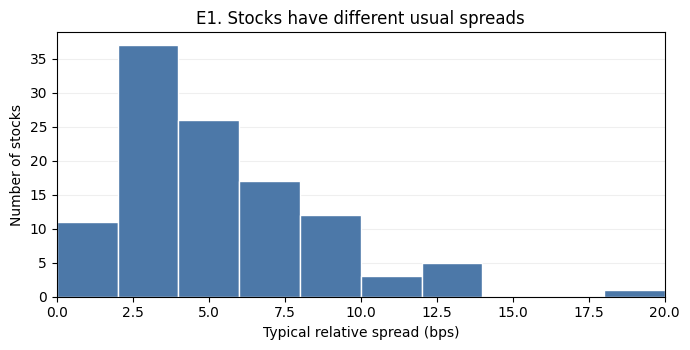

In [ ]:
# E1. Stock differences motivate comparisons with each stock's usual level.
# Development windows only. This cell does not alter model inputs.
e1 = dev_f.assign(
    spread_bps=np.exp(dev_f.log_S1) * 1e4,
    depth=np.exp(dev_f.log_depth1),
    quotes=np.exp(dev_f.log_nupd),
)
stocks = e1.groupby("stock_id")[["spread_bps", "depth", "quotes"]].median()
summary_e1 = stocks.quantile([0.1, 0.5, 0.9]).T
summary_e1.columns = ["p10", "median", "p90"]
summary_e1.index = ["Spread (bps)", "Depth (shares)", "Book-update seconds"]
print(f"{len(stocks)} stocks; one typical value per stock.")
display(summary_e1.round(2))

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(stocks.spread_bps, bins=np.linspace(0, 20, 11),
        color="#4C78A8", edgecolor="white")
ax.set(xlabel="Typical relative spread (bps)", ylabel="Number of stocks",
       title="E1. Stocks have different usual spreads", xlim=(0, 20))
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


**What we find.** Typical spreads range from **2.01 bps at the 10th percentile to 9.41 bps at the 90th percentile**, with a median of **4.69 bps**. Depth differs by about **6.5 times** between those percentiles, and update activity also varies substantially.

**What this motivates.** Compare each stock's current conditions with its own usual levels, and include a stock-mean forecast as a baseline. A 7-bp spread can be unusually wide for one stock and relatively narrow for another. The forecasting pipeline estimates usual levels from the training fold only.


### E2. What do the two targets look like?

We compare future mid-price return with the change in average relative spread:

- **Price return:** the midpoint's percentage change from second 299 to 599, expressed in basis points.
- **Spread change:** `log(S2 / S1)`, where S1 and S2 are the average relative spreads in the first and second halves. Positive values mean widening; negative values mean narrowing.

The histograms show the central 99% for readability. Statistics and correlations use all development observations.


,Price return (bps),Log spread change
Mean,0.244,-0.036
SD,24.778,0.176


Spread widens in 42.1% of stock-windows.
Spearman(price return, log spread change): -0.03


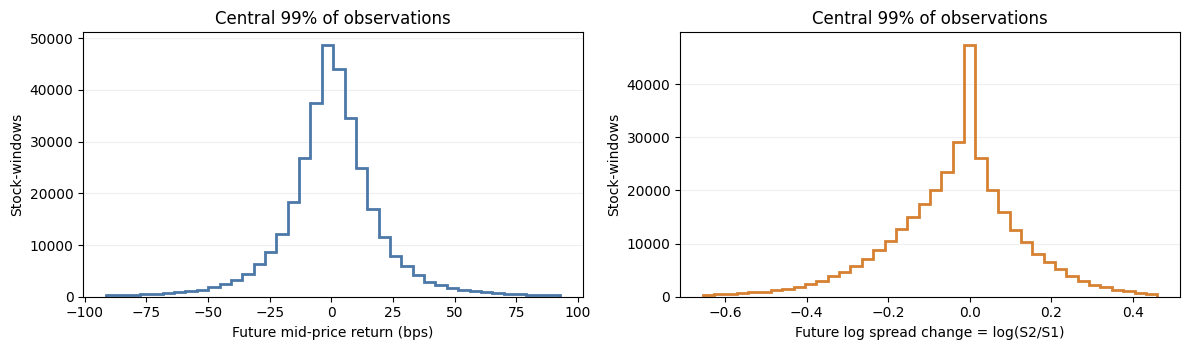

In [ ]:
# E2. Outcome distributions motivate separate price and spread forecasts.
yp, ys = dev_o.y_price, dev_o.y_spread
summary_e2 = pd.DataFrame({
    "Price return (bps)": [yp.mean(), yp.std()],
    "Log spread change": [ys.mean(), ys.std()],
}, index=["Mean", "SD"])
display(summary_e2.round(3))
rho_e2 = yp.corr(ys, method="spearman")
print(f"Spread widens in {(ys > 0).mean():.1%} of stock-windows.")
print(f"Spearman(price return, log spread change): {rho_e2:+.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, y, label, color in [
    (axes[0], yp, "Future mid-price return (bps)", "#4C78A8"),
    (axes[1], ys, "Future log spread change = log(S2/S1)", "#D68132"),
]:
    lo, hi = y.quantile([0.005, 0.995])
    # Show the central 99% without clipping tail observations into edge bins.
    visible = y.between(lo, hi)
    ax.hist(y[visible], bins=np.linspace(lo, hi, 41),
            histtype="step", color=color, linewidth=2)
    ax.set(xlabel=label, ylabel="Stock-windows", title="Central 99% of observations")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
plt.tight_layout()
plt.show()


**What we find.** Price return averages **+0.24 bps**, much smaller than its **24.8-bp standard deviation**. Mean log spread change is **−0.036**, and **42.1%** of observations widen. The targets have little rank association: their Spearman correlation is approximately **−0.03**.

**What this motivates.** Fit separate price and spread forecasts, allowing each target its own model selection. Near-zero correlation does not establish independence. The spread target describes the second-half average rather than the spread at the exit second.


### E3. Which first-half conditions relate to future outcomes?

We retain three comparisons: recent spread relative to S1, first-half volatility, and order-book tilt at second 299. For each condition, we rank observations **within each stock** and divide them into five groups: Q1 is lowest and Q5 highest.

Each point shows the group's mean future outcome. The dashed line shows the overall mean.


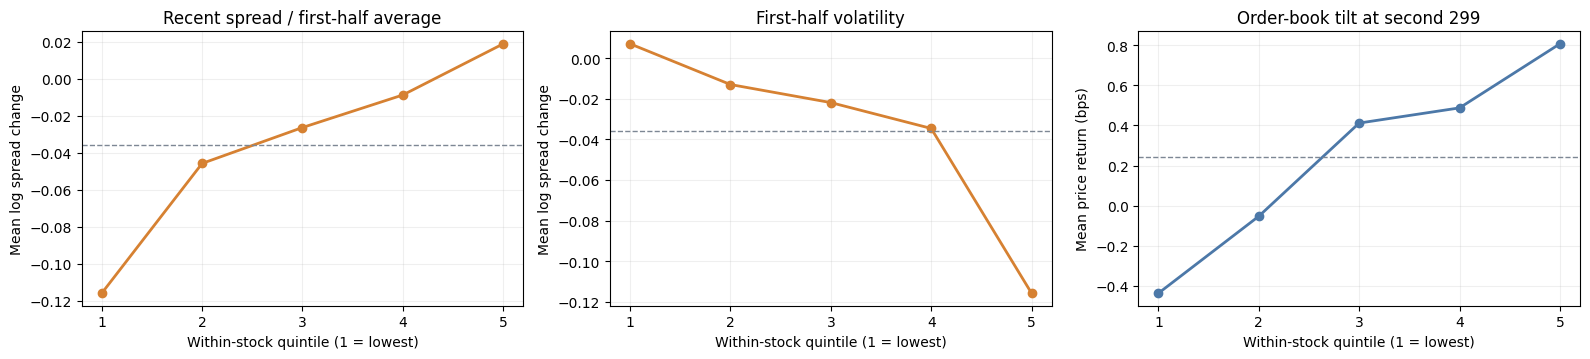

,sp_last60,log_rv,wap_tilt_now
Quintile,,,
1,-0.1160,0.0071,-0.4364
2,-0.0459,-0.0130,-0.0526
3,-0.0265,-0.0219,0.4118
4,-0.0089,-0.0346,0.4875
5,0.0188,-0.1158,0.8069


In [ ]:
# E3. Selected first-half conditions motivate testing ridge and boosting.
# Quintiles rank observations within each stock. These are descriptive means.
d4 = dev_f.join(dev_o[["y_price", "y_spread"]])

def within_stock_quintile(column):
    ranks = d4.groupby("stock_id")[column].rank(pct=True, method="first")
    return np.ceil(ranks * 5).clip(1, 5).astype(int)

conditions_e4 = [
    ("sp_last60", "y_spread", "Recent spread / first-half average", "Mean log spread change", "#D68132"),
    ("log_rv", "y_spread", "First-half volatility", "Mean log spread change", "#D68132"),
    ("wap_tilt_now", "y_price", "Order-book tilt at second 299", "Mean price return (bps)", "#4C78A8"),
]
curves_e4 = {}
fig, axes = plt.subplots(1, 3, figsize=(16, 3.7))
for ax, (feature, target, title, ylabel, color) in zip(axes, conditions_e4):
    q = within_stock_quintile(feature)
    means = d4.groupby(q)[target].mean().reindex(range(1, 6))
    curves_e4[feature] = means
    ax.plot(means.index, means.values, "o-", color=color, linewidth=2)
    ax.axhline(d4[target].mean(), color="#7D8794", linestyle="--", linewidth=1)
    ax.set(title=title, xlabel="Within-stock quintile (1 = lowest)",
           ylabel=ylabel, xticks=range(1, 6))
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()
display(pd.DataFrame(curves_e4).rename_axis("Quintile").round(4))


**What we find.**

- **Recent spread:** mean future log spread change rises from **−0.116 in Q1 to +0.019 in Q5**.
- **Volatility:** the highest-volatility group has more subsequent spread narrowing, with mean log spread change of **−0.116**.
- **Book tilt:** mean future price return rises from **−0.44 to +0.81 bps** across the extreme groups. These effects are small relative to the typical 4.69-bp spread.

**What this motivates.** Compare ridge regression with gradient boosting. Ridge provides a regularized linear baseline; boosting can capture uneven responses such as the volatility pattern. Grouped validation determines which model works best for each target.

These are one-variable descriptive comparisons without uncertainty intervals. The recent-spread condition and spread target both use S1 as a reference, so their association alone does not prove that a spread trend continues after second 299.


### E4. Does market context matter?

We average first-half conditions and future outcomes across stocks within each window to examine common market patterns. We also compare a stock's recent and future price returns after subtracting their respective window averages.

The chart reports Pearson correlations. Market comparisons use window averages; the own-stock comparison uses individual observations after removing those averages.


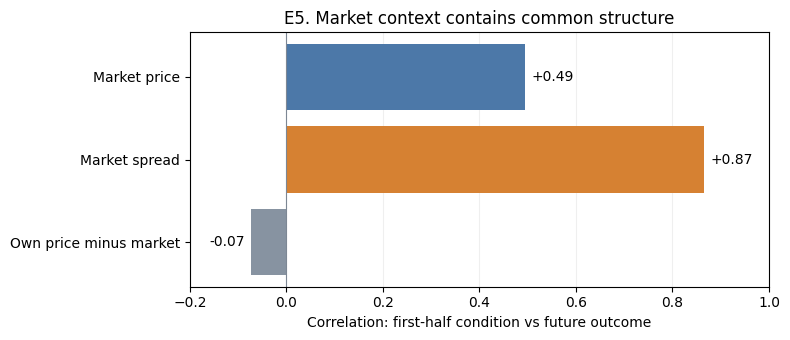

In [ ]:
# E4. Market context motivates other-stock inputs and grouping folds by window.
d5 = dev_f[["stock_id", "time_id", "ret_last60", "sp_last60"]].join(
    dev_o[["y_price", "y_spread"]]
)
market_e5 = d5.groupby("time_id")[[
    "ret_last60", "sp_last60", "y_price", "y_spread"
]].mean()
residual_e5 = d5[["ret_last60", "y_price"]] - d5.groupby("time_id")[[
    "ret_last60", "y_price"
]].transform("mean")
corr_e5 = pd.Series({
    "Market price": market_e5.ret_last60.corr(market_e5.y_price),
    "Market spread": market_e5.sp_last60.corr(market_e5.y_spread),
    "Own price minus market": residual_e5.ret_last60.corr(residual_e5.y_price),
}, name="Pearson correlation")

fig, ax = plt.subplots(figsize=(8, 3.5))
bars = ax.barh(corr_e5.index, corr_e5.values,
               color=["#4C78A8", "#D68132", "#8793A1"])
ax.bar_label(bars, labels=[f"{v:+.2f}" for v in corr_e5], padding=5)
ax.axvline(0, color="#7D8794", linewidth=0.8)
ax.set(xlim=(-0.2, 1), xlabel="Correlation: first-half condition vs future outcome",
       title="E4. Market context contains common structure")
ax.invert_yaxis()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

# Describes common future variation. These future means are NOT model inputs.
window_share_e5 = {}
for target in ["y_price", "y_spread"]:
    y = d5[target]
    window_mean = d5.groupby("time_id")[target].transform("mean")
    window_share_e5[target] = 1 - ((y - window_mean) ** 2).mean() / y.var()
print(f"{len(market_e5):,} development windows.")
print("Window means describe "
      f"{window_share_e5['y_price']:.1%} of price variation and "
      f"{window_share_e5['y_spread']:.1%} of spread-change variation.")
print("Model inputs use other stocks' observed first-half features only.")


**What we find.** Recent market price return correlates **+0.49** with future market return. The recent market spread condition correlates **+0.87** with future market spread change. After removing window averages, the correlation between a stock's own recent and future price returns is **−0.07**.

**What this motivates.** Add first-half features from the other stocks and keep all stocks from the same window in one validation fold. These correlations describe associations, not out-of-sample prediction scores. Future market outcomes are used here for analysis only; model inputs contain observed first-half information.


### How the EDA informs the forecasting pipeline

| Evidence | Modeling choice to evaluate |
|---|---|
| E1: stocks have different normal trading conditions | Stock-relative features and a stock-mean baseline |
| E2: price and spread have different distributions and little rank association | Separate forecasts for the two targets |
| E3: uneven spread responses and small directional price effects | Compare ridge regression and gradient boosting |
| E4: common patterns across stocks in a window | Other-stock first-half features and validation grouped by window |

The EDA motivates these choices. The following sections evaluate their forecasting performance using grouped nested validation.


## 5. Forecasts: baselines and two simple models (H1, H2)

For each target:

| Forecast | Definition |
|---|---|
| zero | no change (`y = 0›) |
| stock mean | the stock's mean target in the training fold |
| persistence | price: keep the current mid (same as zero); spread: the last-60 s mean spread persists, `log(q_last60 / S1)› |
| ridge | median imputation, scaling and ridge with α ∈ {1, 10, 100}, fitted on the training fold |
| HGB | `HistGradientBoostingRegressor› with one fixed, modest setting (`CONFIG["hgb"]›) |
| selected | the model (ridge α or HGB) with the lowest inner out-of-fold RMSE, chosen separately in each outer fold |

**Why these two models.** The EDA shows an uneven, threshold-like pattern for the spread (E3), which suits trees, and a small, mostly linear market signal for price (E3, E4), which suits a regularised linear model. §5.2 tries larger boosted models.

**Nested validation.** There are 5 outer grouped folds. Inside each outer training fold, 3 inner folds give out-of-fold forecasts that we use to pick the model and the trading rule (§6). The chosen models are refit on the full outer training fold and scored once on the outer validation fold, so every development row gets exactly one out-of-fold forecast and one trading decision. The selection rule is fixed in `CONFIG›.

In [ ]:
TARGETS = {"price": "y_price", "spread": "y_spread"}     # y_price in bps; y_spread = log(S2/S1)


def make_head(name):
    if name.startswith("ridge"):
        alpha = float(name.split("=")[1])
        return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha))
    return HistGradientBoostingRegressor(**CONFIG["hgb"])


HEADS = [f"ridge a={a:g}" for a in CONFIG["ridge_alphas"]] + ["HGB"]


def fit_predict(name, X_tr, y_tr, X_te):
    ok = np.isfinite(y_tr)
    return make_head(name).fit(X_tr[ok], y_tr[ok]).predict(X_te)


def baselines(target, f_tr, o_tr, f_te):
    """Zero change, training-fold stock mean, and persistence (in the target's own units)."""
    y = o_tr[TARGETS[target]]
    stock_mean = f_te.stock_id.map(y.groupby(f_tr.stock_id.to_numpy()).mean()).fillna(y.mean()).to_numpy()
    if target == "price":
        persistence = np.zeros(len(f_te))          # keep the current midpoint = zero return
    else:
        persistence = f_te.sp_last60.to_numpy()    # last-60 s mean spread persists: log(q_last60 / S1)
    return {"zero": np.zeros(len(f_te)), "stock mean": stock_mean, "persistence": persistence}


def rmse(y, p):
    ok = np.isfinite(y)
    return float(np.sqrt(np.mean((y[ok] - p[ok]) ** 2)))


# ---- trading policy and quote-based simulation ----
def net_return_bps(o, cost_bps, delay=0):
    """Buy Q at the ask at second 300+delay, sell at the bid at 599; proportional cost per leg.
    The bid/ask fills already charge the spread, so it is not subtracted again."""
    A = o[f"ask_{ENTRY + delay}"].to_numpy()
    B = o[f"bid_{EXIT}"].to_numpy()
    Q, c = CONFIG["quantity"], cost_bps / 1e4
    entry_cash, exit_cash = Q * A * (1 + c), Q * B * (1 - c)
    return 1e4 * (exit_cash - entry_cash) / (Q * A)


def fillable(o, delay=0):
    """Both legs executable for Q shares at the standing quote (otherwise: unresolved)."""
    Q = CONFIG["quantity"]
    return ((o[f"ask_size_{ENTRY + delay}"] >= Q) & (o[f"bid_size_{EXIT}"] >= Q)
            & o[f"ask_{ENTRY + delay}"].notna() & o[f"bid_{EXIT}"].notna()).to_numpy()


def decide(pred_price, pred_spread, q_299, margin_bps, tau, cost_bps):
    """Enter only on information available at second 299: forecasts and the current quote.
    Hurdle = current relative spread + round-trip cost + margin, all in bps."""
    hurdle = q_299 * 1e4 + 2 * cost_bps + margin_bps
    return (pred_price > hurdle) & (pred_spread <= tau)


def rule_grid(policy):
    taus = [float("inf")] if policy == "price only" else CONFIG["taus"]
    # simplest first: no spread filter, then smaller margins; ties keep the earlier rule
    return [(m, t) for t in sorted(taus, reverse=True) for m in CONFIG["margins_bps"]]


def select_rule(policy, pred_price, pred_spread, q_299, net_ref, cost_bps):
    """Pick (margin, tau) maximising mean net bps per opportunity on INNER out-of-fold forecasts."""
    best, rows = None, []
    for m, t in rule_grid(policy):
        enter = decide(pred_price, pred_spread, q_299, m, t, cost_bps)
        n = int(enter.sum())
        score = float(np.where(enter, net_ref, 0.0).mean())
        rows.append({"margin_bps": m, "tau": t, "inner_trades": n, "per_opportunity_bps": score})
        if n >= CONFIG["min_inner_trades"] and (best is None or score > best[2] + 1e-12):
            best = (m, t, score, n)
    return best, pd.DataFrame(rows)

In [ ]:
POLICIES = ["price only", "price + spread"]
REF = CONFIG["reference_cost_bps"]


def inner_forecasts(f_tr, o_tr, seed):
    """Inner grouped out-of-fold forecasts of every head, for both targets."""
    k_in = CONFIG["inner_folds"]
    inner = assign_folds(f_tr.time_id.to_numpy(), k_in, seed=seed)
    preds = {t: {h: np.full(len(f_tr), np.nan) for h in HEADS} for t in TARGETS}
    for j in range(k_in):
        a, b = inner != j, inner == j
        X_a, X_b = fold_features(f_tr[a], f_tr[b])
        for t, col in TARGETS.items():
            y_a = o_tr[col].to_numpy()[a]
            for h in HEADS:
                preds[t][h][b] = fit_predict(h, X_a, y_a, X_b)
    return preds


def nested_cv(dev_f, dev_o):
    oof = dev_f[KEYS + ["fold"]].copy()
    selections, rule_tables, inner_store = [], [], {}
    for k in range(CONFIG["outer_folds"]):
        t0 = perf_counter()
        tr, va = dev_f.fold != k, dev_f.fold == k
        f_tr, o_tr = dev_f[tr].reset_index(drop=True), dev_o[tr].reset_index(drop=True)
        f_va, o_va = dev_f[va].reset_index(drop=True), dev_o[va].reset_index(drop=True)

        # 1) inner folds: choose one head per target by inner RMSE
        ip = inner_forecasts(f_tr, o_tr, seed=100 + k)
        chosen = {t: min(HEADS, key=lambda h: rmse(o_tr[col].to_numpy(), ip[t][h]))
                  for t, col in TARGETS.items()}
        ridge_best = {t: min([h for h in HEADS if h.startswith("ridge")],
                             key=lambda h: rmse(o_tr[col].to_numpy(), ip[t][h])) for t, col in TARGETS.items()}

        # 2) inner folds: choose trading rules on inner forecasts and realised training outcomes
        net_ref = np.where(fillable(o_tr), net_return_bps(o_tr, REF), 0.0)
        rules = {}
        for pol in POLICIES:
            best, tab = select_rule(pol, ip["price"][chosen["price"]], ip["spread"][chosen["spread"]],
                                    f_tr.q_299.to_numpy(), net_ref, REF)
            rules[pol] = best
            rule_tables.append(tab.assign(fold=k, policy=pol))
        inner_store[k] = {"price": ip["price"][chosen["price"]], "spread": ip["spread"][chosen["spread"]],
                          "rows": dev_f.index[tr].to_numpy()}

        # 3) refit on the whole outer-training fold, predict the outer validation fold
        X_tr, X_va = fold_features(f_tr, f_va)
        idx = dev_f.index[va]
        for t, col in TARGETS.items():
            y_tr = o_tr[col].to_numpy()
            for name, p in baselines(t, f_tr, o_tr, f_va).items():
                oof.loc[idx, f"{t}: {name}"] = p
            fitted = {h: fit_predict(h, X_tr, y_tr, X_va) for h in {ridge_best[t], "HGB", chosen[t]}}
            oof.loc[idx, f"{t}: ridge"] = fitted[ridge_best[t]]
            oof.loc[idx, f"{t}: HGB"] = fitted["HGB"]
            oof.loc[idx, f"{t}: selected"] = fitted[chosen[t]]

        # 4) apply the frozen rules to the outer validation fold
        pp, ps = oof.loc[idx, "price: selected"].to_numpy(), oof.loc[idx, "spread: selected"].to_numpy()
        for pol in POLICIES:
            r = rules[pol]
            oof.loc[idx, f"enter: {pol}"] = (decide(pp, ps, f_va.q_299.to_numpy(), r[0], r[1], REF)
                                             if r is not None else False)
        selections.append({"fold": k, "price head": chosen["price"], "spread head": chosen["spread"],
                           **{f"{pol}: margin_bps": (rules[pol] or (None,))[0] for pol in POLICIES},
                           **{f"{pol}: tau": (rules[pol] or (None, None))[1] for pol in POLICIES},
                           **{f"{pol}: inner trades": (rules[pol] or (None, None, None, None))[3]
                              for pol in POLICIES},
                           "minutes": (perf_counter() - t0) / 60})
        print(f"outer fold {k + 1}/{CONFIG['outer_folds']}: heads {chosen} | "
              f"rules {{{', '.join(f'{p}: {rules[p][:2] if rules[p] else None}' for p in POLICIES)}}} | "
              f"{(perf_counter() - t0) / 60:.1f} min")
    for pol in POLICIES:
        oof[f"enter: {pol}"] = oof[f"enter: {pol}"].astype(bool)
    return oof, pd.DataFrame(selections), pd.concat(rule_tables, ignore_index=True), inner_store


started = perf_counter()
oof, selections, rule_tables, inner_store = nested_cv(dev_f, dev_o)
CV_STATUS = f"executed {dt.datetime.now().isoformat(timespec='minutes')} ({(perf_counter() - started) / 60:.1f} min)"
print("Status:", CV_STATUS)
display(selections)

outer fold 1/5: heads {'price': 'ridge a=1', 'spread': 'HGB'} | rules {price only: (2.0, inf), price + spread: (2.0, inf)} | 2.6 min
outer fold 2/5: heads {'price': 'ridge a=100', 'spread': 'HGB'} | rules {price only: (2.0, inf), price + spread: (2.0, inf)} | 2.7 min
outer fold 3/5: heads {'price': 'ridge a=100', 'spread': 'HGB'} | rules {price only: (2.0, inf), price + spread: (2.0, inf)} | 2.6 min
outer fold 4/5: heads {'price': 'ridge a=1', 'spread': 'HGB'} | rules {price only: (2.0, inf), price + spread: (2.0, inf)} | 2.5 min
outer fold 5/5: heads {'price': 'ridge a=1', 'spread': 'HGB'} | rules {price only: (2.0, inf), price + spread: (2.0, inf)} | 2.5 min
Status: executed 2026-11-05T03:48 (12.9 min)


,fold,price head,spread head,price only: margin_bps,price + spread: margin_bps,price only: tau,price + spread: tau,price only: inner trades,price + spread: inner trades,minutes
0,0,ridge a=1,HGB,2.0,2.0,inf,inf,16323,16323,2.616872
1,1,ridge a=100,HGB,2.0,2.0,inf,inf,18055,18055,2.698553
2,2,ridge a=100,HGB,2.0,2.0,inf,inf,17184,17184,2.571455
3,3,ridge a=1,HGB,2.0,2.0,inf,inf,17806,17806,2.478072
4,4,ridge a=1,HGB,2.0,2.0,inf,inf,17156,17156,2.499424


### 5.1 Forecast accuracy (outer folds)

MAE, RMSE and R² for each model and target, with R² by stock group and the RMSE gain over each baseline. RMSE is in each target's own units, so do not compare it across targets. The calibration plots show the mean outcome in each decile of the selected model's forecast.

Validation status: executed 2026-11-05T03:48 (12.9 min) | development set, 5 outer x 3 inner grouped folds

PRICE head: y_price = m599/m299 - 1, in bps  (do not compare RMSE across the two targets)


,MAE,RMSE,R2,R2 low-activity stocks,R2 high-activity stocks,R2 min-spread-bound,median per-stock R2,RMSE gain vs zero,RMSE gain vs stock mean,RMSE gain vs persistence
zero,15.4169,24.7793,-0.0001,-0.0001,-0.0001,-0.0001,-0.0002,0.0000,0.0001,0.0000
stock mean,15.4258,24.7828,-0.0004,-0.0006,-0.0003,-0.0003,-0.0005,-0.0001,0.0000,-0.0001
persistence,15.4169,24.7793,-0.0001,-0.0001,-0.0001,-0.0001,-0.0002,0.0000,0.0001,0.0000
ridge,15.0470,24.0080,0.0612,0.0644,0.0669,0.0506,0.0643,0.0311,0.0313,0.0311
HGB,15.1655,24.2703,0.0406,0.0468,0.0426,0.0345,0.0424,0.0205,0.0207,0.0205
selected,15.0470,24.0080,0.0612,0.0644,0.0669,0.0506,0.0643,0.0311,0.0313,0.0311



SPREAD head: y_spread = log(S2/S1)  (do not compare RMSE across the two targets)


,MAE,RMSE,R2,R2 low-activity stocks,R2 high-activity stocks,R2 min-spread-bound,median per-stock R2,RMSE gain vs zero,RMSE gain vs stock mean,RMSE gain vs persistence
zero,0.1257,0.1792,-0.0413,-0.0351,-0.0496,-0.0449,-0.0478,0.0000,-0.0218,0.1095
stock mean,0.1249,0.1753,0.0027,0.0011,0.0076,0.0094,-0.0006,0.0213,0.0000,0.1284
persistence,0.1462,0.2012,-0.3130,-0.4034,-0.0026,0.2533,-0.3574,-0.1229,-0.1474,0.0000
ridge,0.1100,0.1478,0.2909,0.2686,0.3421,0.4457,0.2783,0.1748,0.1568,0.2651
HGB,0.1034,0.1417,0.3484,0.3114,0.4658,0.6237,0.3300,0.2090,0.1917,0.2955
selected,0.1034,0.1417,0.3484,0.3114,0.4658,0.6237,0.3300,0.2090,0.1917,0.2955


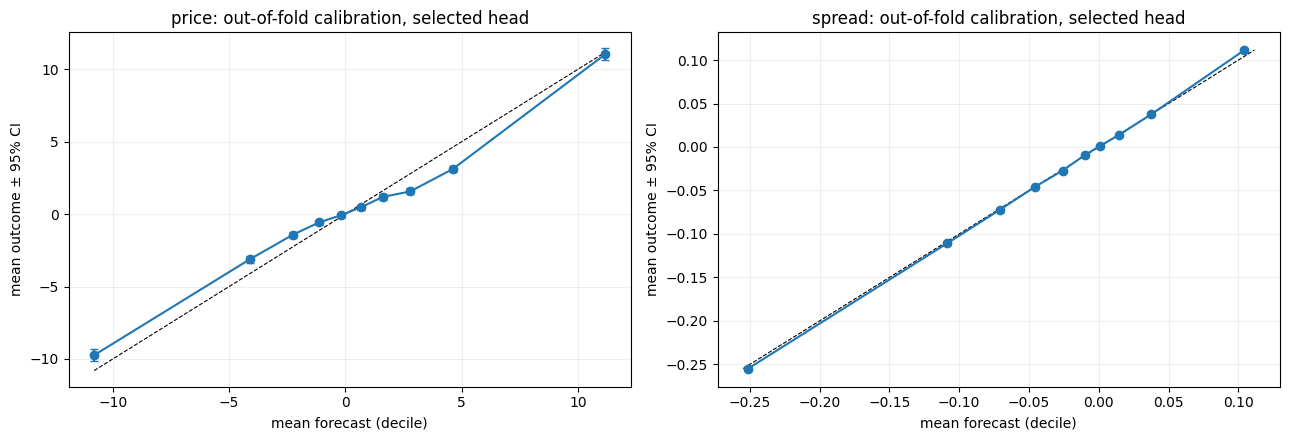

In [ ]:
# Forecast skill: genuinely out-of-fold (outer validation) predictions on the development set.
print(f"Validation status: {CV_STATUS} | development set, {CONFIG['outer_folds']} outer x "
      f"{CONFIG['inner_folds']} inner grouped folds")

def r2(y, p):
    ok = np.isfinite(y) & np.isfinite(p)
    return float(1 - ((y[ok] - p[ok]) ** 2).sum() / ((y[ok] - y[ok].mean()) ** 2).sum())


def forecast_table(t):
    y = dev_o[TARGETS[t]].to_numpy()
    models = [c.split(": ")[1] for c in oof.columns if c.startswith(f"{t}: ")]
    rows = {}
    for m in models:
        p = oof[f"{t}: {m}"].to_numpy()
        ok = np.isfinite(y)
        rows[m] = {"MAE": np.mean(np.abs(y[ok] - p[ok])), "RMSE": rmse(y, p), "R2": r2(y, p),
                   "R2 low-activity stocks": r2(y[ACTIVITY == "low"], p[ACTIVITY == "low"]),
                   "R2 high-activity stocks": r2(y[ACTIVITY == "high"], p[ACTIVITY == "high"]),
                   "R2 min-spread-bound": r2(y[MIN_BOUND], p[MIN_BOUND]),
                   "median per-stock R2": pd.Series({s: r2(y[g], p[g]) for s, g in
                                                     dev_f.groupby("stock_id").indices.items()}).median()}
    tab = pd.DataFrame(rows).T
    for b in ["zero", "stock mean", "persistence"]:
        tab[f"RMSE gain vs {b}"] = 1 - tab.RMSE / tab.loc[b, "RMSE"]
    return tab


units = {"price": "y_price = m599/m299 - 1, in bps", "spread": "y_spread = log(S2/S1)"}
for t in TARGETS:
    print(f"\n{t.upper()} head: {units[t]}  (do not compare RMSE across the two targets)")
    display(forecast_table(t).round(4))

# binned calibration: mean outcome by decile of the selected head's forecast
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, t in zip(axes, TARGETS):
    y, p = dev_o[TARGETS[t]].to_numpy(), oof[f"{t}: selected"].to_numpy()
    b = pd.qcut(p, 10, labels=False, duplicates="drop")
    cal = pd.DataFrame({"p": p, "y": y}).groupby(b).agg(pred=("p", "mean"), actual=("y", "mean"),
                                                        se=("y", "sem"))
    ax.errorbar(cal.pred, cal.actual, yerr=1.96 * cal.se, marker="o", capsize=3)
    lim = [min(cal.pred.min(), cal.actual.min()), max(cal.pred.max(), cal.actual.max())]
    ax.plot(lim, lim, "k--", lw=0.8)
    ax.set(xlabel="mean forecast (decile)", ylabel="mean outcome ± 95% CI",
           title=f"{t}: out-of-fold calibration, selected head")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Result.** H1 holds: gradient boosting reaches R² 0.348 on the spread change and is chosen in every fold, compared with about 0 for the stock mean and −0.31 for persistence. Ridge already gets 0.29, so most of the structure is fairly simple and the trees add the rest. H2 holds, but weakly: ridge reaches R² 0.061 on price and HGB does worse (0.041). The price signal is small and close to linear.

### 5.2 Larger models

§5 keeps the models small on purpose so that the trading section tests a simple, fixed pipeline. Here we ask how far forecast accuracy can go with the same leakage-safe setup. We make three changes, all chosen on the development folds:

| Change | Reason |
|---|---|
| Trade prints (count, volume, trade-price volatility, time since last trade, VWAP vs mid) and the spread's full path (quantiles, number of changes, trend, level-2 gap, depth trend) | E3 shows the recent spread trend continues, so the full path should help. Trades are a second record of activity. |
| More market context: leave-one-out market means for every input, cross-stock dispersion, each stock's typical target (training fold only) and the stock ID | E4: 17–23% of each outcome is shared across stocks. E1: stocks differ several-fold. |
| Larger models: the spread uses LightGBM with 3,000 trees averaged over 3 seeds; the price uses a 50/50 blend of a Huber-loss LightGBM and a ridge with α = 3,000 | Trees fit the uneven spread pattern. For price, the Huber loss limits the effect of jumps, the ridge stays stable, and averaging the two helps. |

All inputs still use seconds 0–299 only, everything is fitted on the training fold, and the folds are the same as in §5. The trading results in §6–§9 still use the §5 models.

*Run time:* the two cells below take about 2.5 hours on a standard Colab runtime (5.2b takes about 28 minutes per fold).

In [ ]:
# 5.2a Extra first-half inputs (seconds 0..299 only): the spread's path and the trade prints.
import lightgbm as lgb

SEC = np.arange(CUT)


def extra_stock(stock_id):
    tids, g, _ = dense_grid(load_stock("book", stock_id))
    bp, ap = g["bid_price1"][:, :CUT], g["ask_price1"][:, :CUT]
    mid = (ap + bp) / 2
    q = (ap - bp) / mid
    lq = np.log(q)
    med = np.nanmedian(q, axis=1, keepdims=True)
    dq = np.abs(np.diff(q, axis=1)) > 1e-12
    chg_sec = np.where(np.concatenate([np.zeros((len(tids), 1), bool), dq], axis=1), SEC, -1)
    xc = SEC - SEC.mean()
    ok = np.isfinite(lq)
    lq0 = np.where(ok, lq, 0.0)
    xm = (ok * xc).sum(1) / ok.sum(1)
    slope = ((lq0 - np.nanmean(lq, 1, keepdims=True)) * (xc - xm[:, None]) * ok).sum(1) / (((xc - xm[:, None]) ** 2) * ok).sum(1)
    q2 = (g["ask_price2"][:, :CUT] - g["bid_price2"][:, :CUT]) / mid
    dep = g["bid_size1"][:, :CUT] + g["ask_size1"][:, :CUT] + np.nan_to_num(g["bid_size2"][:, :CUT]) + np.nan_to_num(g["ask_size2"][:, :CUT])
    wap = (bp * g["ask_size1"][:, :CUT] + ap * g["bid_size1"][:, :CUT]) / (g["bid_size1"][:, :CUT] + g["ask_size1"][:, :CUT])
    lr = np.diff(np.log(wap), axis=1)
    with np.errstate(all="ignore"):
        f = pd.DataFrame({
            "stock_id": int(stock_id), "time_id": tids,
            "x_lq_p10": np.nanpercentile(lq, 10, axis=1), "x_lq_p50": np.nanpercentile(lq, 50, axis=1),
            "x_lq_p90": np.nanpercentile(lq, 90, axis=1), "x_lq_max60": np.nanmax(lq[:, -60:], axis=1),
            "x_lq_min60": np.nanmin(lq[:, -60:], axis=1), "x_lq_120": np.log(np.nanmean(q[:, -120:], axis=1)),
            "x_lq_200_240": np.log(np.nanmean(q[:, 200:240], axis=1)),
            "x_sp_slope": slope * 100, "x_n_spchg": np.log1p(dq.sum(1)), "x_n_spchg60": np.log1p(dq[:, -60:].sum(1)),
            "x_since_spchg": CUT - 1 - chg_sec.max(1),
            "x_frac_wide": np.nanmean(q > 1.5 * med, axis=1), "x_frac_wide60": np.nanmean(q[:, -60:] > 1.5 * med, axis=1),
            "x_lq_now_vs_med": lq[:, -1] - np.log(med[:, 0]),
            "x_lq2_60": np.log(np.nanmean(q2[:, -60:], axis=1)),
            "x_l2gap": np.log(np.nanmean(q2[:, -60:], axis=1)) - np.log(np.nanmean(q[:, -60:], axis=1)),
            "x_ldep60": np.log(np.nanmean(dep[:, -60:], axis=1)),
            "x_ldep_trend": np.log(np.nanmean(dep[:, -60:], axis=1)) - np.log(np.nanmean(dep[:, :240], axis=1)),
            "x_rv30": np.log(np.sqrt(np.nansum(lr[:, -30:] ** 2, axis=1)) + 1e-5),
            "x_rv_first150": np.log(np.sqrt(np.nansum(lr[:, :150] ** 2, axis=1)) + 1e-5),
        })
    tr = load_stock("trade", stock_id)
    tr = tr[tr.seconds_in_bucket < CUT].sort_values(["time_id", "seconds_in_bucket"])
    tr["lr"] = np.log(tr.price).groupby(tr.time_id).diff()
    tr["notional"] = tr.price * tr["size"]
    a = tr.groupby("time_id").agg(n=("size", "size"), vol=("size", "sum"), oc=("order_count", "sum"),
                                  last=("seconds_in_bucket", "max"), rvt=("lr", lambda s: np.sqrt((s ** 2).sum())),
                                  notional=("notional", "sum"))
    b = tr[tr.seconds_in_bucket >= CUT - 60].groupby("time_id").agg(n60=("size", "size"), vol60=("size", "sum"),
                                                                    notional60=("notional", "sum"))
    a = a.join(b, how="left").reindex(tids)
    mid299 = pd.Series(mid[:, -1], index=tids)
    f["t_ln"] = np.log1p(a.n.fillna(0).to_numpy())
    f["t_lvol"] = np.log1p(a.vol.fillna(0).to_numpy())
    f["t_loc"] = np.log1p(a.oc.fillna(0).to_numpy())
    f["t_ln60"] = np.log1p(a.n60.fillna(0).to_numpy())
    f["t_lvol60"] = np.log1p(a.vol60.fillna(0).to_numpy())
    f["t_since"] = (CUT - 1 - a["last"]).fillna(CUT).to_numpy()
    f["t_lrv"] = np.log(a.rvt.fillna(0).to_numpy() + 1e-5)
    f["t_avgsize"] = np.log1p((a.vol / a.n).to_numpy())
    f["t_vwap_vs_mid"] = ((a.notional / a.vol / mid299 - 1) * 1e4).to_numpy()
    f["t_vwap60_vs_mid"] = ((a.notional60 / a.vol60 / mid299 - 1) * 1e4).to_numpy()
    f["t_per_upd"] = f["t_ln"] - np.log1p(g["upd"][:, :CUT].sum(1))
    return f


t0 = perf_counter()
EXTRA = pd.concat([extra_stock(s) for s in stock_list], ignore_index=True)
print(f"Built extra inputs in {(perf_counter() - t0) / 60:.1f} min")
XCOLS = [c for c in EXTRA.columns if c not in KEYS]
# merged copies only: dev_f / bench_f stay untouched for the rest of the notebook
dev_x = dev_f.merge(EXTRA, on=KEYS, how="left")
bench_x = bench_f.merge(EXTRA, on=KEYS, how="left")
assert dev_x[KEYS].equals(dev_f[KEYS]) and bench_x[KEYS].equals(bench_f[KEYS])
print(f"{len(XCOLS)} extra inputs for {len(EXTRA):,} stock-windows")

Built extra inputs in 6.2 min
31 extra inputs for 428,932 stock-windows


In [ ]:
# 5.2b Upgraded models under the same outer grouped folds as §5. Every statistic is fitted on the training fold.
EXTRA_MKT = [c for c in BASE if c not in MKT_SRC]
UP_TARGETS = {"spread": "y_spread", "price": "y_price"}


def upgraded_features(tr, te, y_tr):
    """§3 fold features + market (leave-one-out), relative, dispersion, stock-level and extra inputs."""
    st_mean = {t: pd.Series(y[np.isfinite(y)]).groupby(tr.stock_id.to_numpy()[np.isfinite(y)]).mean() for t, y in y_tr.items()}
    st_std = {t: pd.Series(y[np.isfinite(y)]).groupby(tr.stock_id.to_numpy()[np.isfinite(y)]).std() for t, y in y_tr.items()}
    out = []
    for d, X in zip((tr, te), fold_features(tr, te)):
        X = X.copy()
        for c in EXTRA_MKT:
            X["mkt_" + c] = leave_one_out_mean(d, c).to_numpy()
        for c in ["sp_last30", "sp_last10", "sp_now", "log_rv", "ret_last60", "ret_last10", "imb_now", "log_nupd"]:
            X["rel_" + c] = X[c] - X["mkt_" + c]
        for c in ["ret_last60", "ret_0_299", "sp_last60"]:
            X["xsd_" + c] = d.groupby("time_id")[c].transform("std").to_numpy()
        for t in y_tr:
            X[f"te_{t}"] = d.stock_id.map(st_mean[t]).to_numpy()
            X[f"tsd_{t}"] = d.stock_id.map(st_std[t]).to_numpy()
        for c in XCOLS:
            X[c] = d[c].to_numpy()
        for c in ["x_lq_p50", "x_n_spchg", "t_ln", "t_lvol", "t_lrv", "x_frac_wide", "t_since"]:
            X["mkt_" + c] = leave_one_out_mean(d, c).to_numpy()
            X[c + "_vs_stock"] = d[c].to_numpy() - d.stock_id.map(tr.groupby("stock_id")[c].mean()).to_numpy()
        X["stock_id"] = pd.Categorical(d.stock_id.to_numpy(), categories=sorted(tr.stock_id.unique()))
        out.append(X)
    return out


LGB_BASE = dict(n_estimators=1500, learning_rate=0.03, num_leaves=63, min_child_samples=200, subsample=0.8,
                subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0, verbose=-1)
SPREAD_LGB = {**LGB_BASE, "n_estimators": 3000, "learning_rate": 0.015, "num_leaves": 127, "min_child_samples": 100}
PRICE_LGB = {**LGB_BASE, "objective": "huber", "alpha": 30.0}
UP_SEEDS = [0, 1, 2]


def upgraded_predict(Xa, ya, Xb):
    """Spread: big LightGBM averaged over seeds. Price: 50/50 Huber LightGBM + ridge (α = 3000)."""
    num = [c for c in Xa.columns if c != "stock_id"]
    ys, yp = ya["spread"], ya["price"]
    ok_s, ok_p = np.isfinite(ys), np.isfinite(yp)
    sp = np.mean([lgb.LGBMRegressor(**SPREAD_LGB, random_state=s).fit(Xa[ok_s], ys[ok_s]).predict(Xb) for s in UP_SEEDS], axis=0)
    p_h = lgb.LGBMRegressor(**PRICE_LGB).fit(Xa[ok_p], yp[ok_p]).predict(Xb)
    p_r = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=3000)).fit(Xa.loc[ok_p, num], yp[ok_p]).predict(Xb[num])
    return sp, 0.5 * p_h + 0.5 * p_r


def r2_score_(y, p):
    ok = np.isfinite(y) & np.isfinite(p)
    return float(1 - np.mean((y[ok] - p[ok]) ** 2) / np.var(y[ok]))


up_oof = dev_f[KEYS].copy()
for k in range(CONFIG["outer_folds"]):
    t0 = perf_counter()
    a, b = (dev_x.fold != k).to_numpy(), (dev_x.fold == k).to_numpy()
    y_a = {t: dev_o[c].to_numpy()[a] for t, c in UP_TARGETS.items()}
    Xa, Xb = upgraded_features(dev_x[a].reset_index(drop=True), dev_x[b].reset_index(drop=True), y_a)
    sp, pr = upgraded_predict(Xa, y_a, Xb)
    up_oof.loc[b, "spread: upgraded"], up_oof.loc[b, "price: upgraded"] = sp, pr
    print(f"outer fold {k + 1}/{CONFIG['outer_folds']}: {Xa.shape[1]} inputs | {(perf_counter() - t0) / 60:.1f} min")

assert up_oof[KEYS].equals(oof[KEYS])
UPGRADE_CV = pd.DataFrame({
    t: {"§5 selected head": r2_score_(dev_o[c].to_numpy(), oof[f"{t}: selected"].to_numpy()),
        "upgraded model": r2_score_(dev_o[c].to_numpy(), up_oof[f"{t}: upgraded"].to_numpy())}
    for t, c in UP_TARGETS.items()}).T
UPGRADE_CV["gain"] = UPGRADE_CV["upgraded model"] / UPGRADE_CV["§5 selected head"] - 1
display(UPGRADE_CV.style.format({"§5 selected head": "{:.3f}", "upgraded model": "{:.3f}", "gain": "{:+.0%}"})
        .set_caption("Out-of-fold R² on the development windows (same outer folds as §5)"))

NameError: name 'BASE' is not defined

**Result.** With the same folds, the extra inputs and larger models improve both targets:

| Out-of-fold R² | §5 model | Larger model | Gain |
|---|---|---|---|
| Spread change | 0.348 (HGB) | 0.380 | +9% |
| Price change | 0.061 (ridge) | 0.070 | +14% |

Price stays hard to predict, which is expected for five-minute returns. §9.1 tests both models once on the holdout.

### 5.3 Drivers and unseen stocks

Two checks on the larger models:

1. **Drivers.** SHAP values split each forecast into contributions from each input. The chart ranks inputs by mean absolute contribution, using models fitted on folds 2–5 and explained on a sample from fold 1.
2. **Unseen stocks.** The earlier scores hold out windows, but every stock appears in training. Here we also split the stocks into five groups and test on (stock group k) × (window fold k). The "unseen" model trains only on other stocks in other windows and gets no stock-specific inputs (stock ID, stock means). It is compared on the same rows with a model that has seen those stocks. Both use a smaller LightGBM (600 trees) to save time; the cell takes about 30 minutes.

In [ ]:
# 5.3 (a) What drives each forecast; (b) does the spread model work on stocks and windows it has never seen?
SMALL_LGB = {**LGB_BASE, "n_estimators": 600, "learning_rate": 0.06}
STOCK_SPECIFIC = lambda c: c == "stock_id" or c.startswith(("te_", "tsd_")) or c.endswith("_vs_stock")

t0 = perf_counter()
up_checks = {"drivers": {}, "unseen": []}
# (a) drivers: mean |SHAP contribution| on a sample of outer fold 1, models fitted on the other folds
a, b = (dev_x.fold != 0).to_numpy(), (dev_x.fold == 0).to_numpy()
y_a = {t: dev_o[c].to_numpy()[a] for t, c in UP_TARGETS.items()}
Xa, Xb = upgraded_features(dev_x[a].reset_index(drop=True), dev_x[b].reset_index(drop=True), y_a)
Xs = Xb.sample(20_000, random_state=0)
for t, params in [("spread", SMALL_LGB), ("price", {**SMALL_LGB, "objective": "huber", "alpha": 30.0})]:
    ok = np.isfinite(y_a[t])
    m = lgb.LGBMRegressor(**params, random_state=0).fit(Xa[ok], y_a[t][ok])
    contrib = np.abs(m.predict(Xs, pred_contrib=True)[:, :-1]).mean(0)
    up_checks["drivers"][t] = dict(zip(Xa.columns, contrib.tolist()))
# (b) unseen stocks AND unseen windows: split stocks into 5 groups and test on (stock group k) x (window fold k);
# training uses only other stocks in other windows, so neither the stock nor the window's market move is seen.
stocks = np.random.default_rng(7).permutation(sorted(dev_x.stock_id.unique()))
sfold = dev_x.stock_id.map(dict(zip(stocks, np.arange(len(stocks)) % CONFIG["outer_folds"]))).to_numpy()
for k in range(CONFIG["outer_folds"]):
    test = ((dev_x.fold == k).to_numpy()) & (sfold == k)
    for setting, train in [("seen stocks", (dev_x.fold != k).to_numpy()),
                           ("unseen stocks", (dev_x.fold != k).to_numpy() & (sfold != k))]:
        y_tr = {t: dev_o[c].to_numpy()[train] for t, c in UP_TARGETS.items()}
        Xa, Xb = upgraded_features(dev_x[train].reset_index(drop=True), dev_x[test].reset_index(drop=True), y_tr)
        cols = [c for c in Xa.columns if not (setting == "unseen stocks" and STOCK_SPECIFIC(c))]
        ok = np.isfinite(y_tr["spread"])
        p = lgb.LGBMRegressor(**SMALL_LGB, random_state=0).fit(Xa.loc[ok, cols], y_tr["spread"][ok]).predict(Xb[cols])
        up_checks["unseen"].append({"fold": k, "setting": setting, "r2": r2_score_(dev_o.y_spread.to_numpy()[test], p),
                                    "rows": int(test.sum())})
    print(f"fold {k + 1}: {(perf_counter() - t0) / 60:.1f} min")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (t, colour) in zip(axes, [("spread", "#2a78d6"), ("price", "#eb6834")]):
    s = pd.Series(up_checks["drivers"][t]).sort_values().tail(12)
    ax.barh(s.index, s.values / s.sum(), color=colour)
    ax.set(title=f"{t} forecast: top 12 inputs (share of the top-12 contribution)", xlabel="mean |SHAP contribution|, normalised")
    ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()
unseen = pd.DataFrame(up_checks["unseen"]).pivot(index="fold", columns="setting", values="r2")
unseen.loc["mean"] = unseen.mean()
display(unseen.round(3).style.set_caption("Spread R² on the same test rows: stocks seen in training vs never seen"))

**Result.** On stocks it has never seen, the spread model still reaches an average R² of 0.28, compared with 0.32 on the same rows when those stocks are in training. Most of the spread skill carries over to new stocks.

## 6. Trading simulation (H3, H4)

**Policies** (long only, at most one trade per stock and window, closed inside the window, same timing, size and fees for all):

| Policy | Enter when |
|---|---|
| Cash | never (zero return) |
| Price only | forecast `y_price› > current relative spread + 2 × fee per side + margin |
| Price + spread | the same price rule and forecast `y_spread ≤ τ› |

The entry hurdle only uses the quote at second 299; actual results come from the fill simulation. In each outer fold the rule is picked on the inner out-of-fold forecasts and realised training outcomes, from a small fixed grid: margin in {0, 1, 2, 5} bp and τ in {log 0.9, 0, log 1.1, ∞}, where ∞ means no spread filter. The objective is mean net bps per opportunity at the reference fee, among rules with at least 200 inner trades, and ties go to the simpler rule.

**Simulation.** Buy one share at the ask at second 300 and sell at the bid at 599, with a proportional fee per side of 0, 0.5 or 1 bp (0.5 is the reference):

`net_bps = 10,000 × (Q·B·(1 − c_out) − Q·A·(1 + c_in)) / (Q·A)›

Crossing the bid and ask already pays the spread, so it is not subtracted again. A leg with no quote or size would count as unresolved rather than being dropped. We report net bps per trade and per opportunity (no trade counts as 0). Per opportunity is the main metric because it includes the trades not taken. Prices are normalised and `time_id›s are shuffled, so we cannot report dollar P&L, an equity curve, a Sharpe ratio or drawdown.

*Note:* the inner folds chose no spread filter (τ = ∞) in every fold, so the "price + spread" rows are identical to "price only". This is the H4 result, explained in §7.

In [ ]:
# Simulated trading on the outer validation folds: decisions were frozen before each fold was seen.
print(f"Validation status: {CV_STATUS} | reference cost {REF} bp per side | Q = {CONFIG['quantity']} share")


def policy_summary(enter, cost_bps, delay=0, extra_mask=None):
    net = net_return_bps(dev_o, cost_bps, delay)
    can = fillable(dev_o, delay)
    enter = np.asarray(enter, bool) & (True if extra_mask is None else extra_mask)
    done = enter & can
    per_opp = np.where(done, net, 0.0)
    tr = net[done]
    return {"opportunities": len(enter), "entries": int(enter.sum()), "completed": int(done.sum()),
            "unresolved": int((enter & ~can).sum()), "trade frequency": enter.mean(),
            "net bps per trade": tr.mean() if len(tr) else np.nan,
            "net bps per opportunity": per_opp.mean(),
            "win rate": (tr > 0).mean() if len(tr) else np.nan,
            "5th pct trade bps": np.percentile(tr, 5) if len(tr) else np.nan,
            "worst trade bps": tr.min() if len(tr) else np.nan}


ENTER = {"cash": np.zeros(len(oof), bool), **{p: oof[f"enter: {p}"].to_numpy() for p in POLICIES}}
results = pd.DataFrame({p: policy_summary(e, REF) for p, e in ENTER.items()}).T
display(results.round(3))


def paired_bootstrap(a, b, groups, n=CONFIG["bootstrap_resamples"], seed=CONFIG["bootstrap_seed"]):
    """Mean of (a - b) per opportunity with a 95% interval, resampling whole time_id groups."""
    d = pd.DataFrame({"d": a - b, "g": groups}).groupby("g").d.agg(["sum", "count"])
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(d), (n, len(d)))
    boot = d["sum"].to_numpy()[idx].sum(1) / d["count"].to_numpy()[idx].sum(1)
    return (a - b).mean(), np.percentile(boot, 2.5), np.percentile(boot, 97.5)


def per_opportunity(enter, cost_bps, delay=0):
    return np.where(np.asarray(enter, bool) & fillable(dev_o, delay), net_return_bps(dev_o, cost_bps, delay), 0.0)


tid = dev_f.time_id.to_numpy()
comb, base = per_opportunity(ENTER["price + spread"], REF), per_opportunity(ENTER["price only"], REF)
m, lo, hi = paired_bootstrap(comb, base, tid)
print(f"Price + spread minus price only, per opportunity: {m:+.4f} bps (95% CI {lo:+.4f} to {hi:+.4f}, "
      f"{CONFIG['bootstrap_resamples']} time_id-cluster resamples)")
for p in POLICIES:
    m, lo, hi = paired_bootstrap(per_opportunity(ENTER[p], REF), np.zeros(len(tid)), tid)
    print(f"{p} minus cash: {m:+.4f} bps per opportunity (95% CI {lo:+.4f} to {hi:+.4f})")

# window-level t: mean trade return per traded window (same definition as the holdout in §9)
done_dev = ENTER["price only"] & fillable(dev_o)
w_dev = pd.Series(net_return_bps(dev_o, REF)[done_dev]).groupby(tid[done_dev]).mean()
print(f"Window-level t, price only: {w_dev.mean() / w_dev.std() * np.sqrt(len(w_dev)):.2f} "
      f"over {len(w_dev):,} traded windows")

### 6.1 Sensitivity

1. **Fixed decisions** under each fee level, later entry (decision still at 299, entry at 302, 305 or 310), and skipping entries where the ask is stale.
2. **Retuned rules:** each fold's rule is picked again under each fee level from the same inner forecasts. This answers a different question from (1), so it is a separate table.
3. **Groups:** results by stock activity tercile and by the minimum-spread proxy.

*Result:* the price-only rule stays positive at 1 bp per side (+0.26 bps per opportunity), with entry delayed 2 to 10 seconds (+4.2 to +4.9 bps per trade), when stale asks are skipped, and in every activity group.

In [ ]:
# Sensitivity of the FIXED policies (decisions unchanged) to costs, entry delay and stale quotes,
# then a retuned comparison where rules are re-selected under each cost scenario.
rows = []
for p in POLICIES:
    for c in CONFIG["cost_scenarios_bps"]:
        rows.append({"policy": p, "check": f"cost {c} bp/side", **policy_summary(ENTER[p], c)})
    for d in CONFIG["entry_delays"][1:]:
        rows.append({"policy": p, "check": f"entry delay +{d} s", **policy_summary(ENTER[p], REF, delay=d)})
    for max_age in [CONFIG["stale_quote_seconds"], 2]:
        fresh = (dev_o[f"age_{ENTRY}"] <= max_age).to_numpy()
        rows.append({"policy": p, "check": f"skip entries on asks older than {max_age} s",
                     **policy_summary(ENTER[p], REF, extra_mask=fresh)})
sens = pd.DataFrame(rows).set_index(["policy", "check"])
display(sens[["entries", "net bps per trade", "net bps per opportunity", "win rate"]].round(3))

# retuned: re-select each fold's rule under each cost, using the stored inner forecasts
retuned = []
for c in CONFIG["cost_scenarios_bps"]:
    enter = {p: np.zeros(len(dev_f), bool) for p in POLICIES}
    for k, st in inner_store.items():
        f_tr, o_tr = dev_f.loc[st["rows"]], dev_o.loc[st["rows"]]
        net_c = np.where(fillable(o_tr), net_return_bps(o_tr, c), 0.0)
        va = (dev_f.fold == k).to_numpy()
        for p in POLICIES:
            best, _ = select_rule(p, st["price"], st["spread"], f_tr.q_299.to_numpy(), net_c, c)
            if best is not None:
                enter[p][va] = decide(oof.loc[va, "price: selected"].to_numpy(), oof.loc[va, "spread: selected"].to_numpy(),
                                      dev_f.q_299.to_numpy()[va], best[0], best[1], c)
    for p in POLICIES:
        retuned.append({"cost bp/side": c, "policy": p, **policy_summary(enter[p], c)})
display(pd.DataFrame(retuned).set_index(["cost bp/side", "policy"])[
    ["entries", "net bps per trade", "net bps per opportunity", "win rate"]].round(3))

# by stock activity group and minimum-spread proxy, reference cost
grp = []
for p in POLICIES:
    for name, mask in [*((f"{a} activity", (ACTIVITY == a).to_numpy()) for a in ["low", "mid", "high"]),
                       ("min-spread-bound", MIN_BOUND), ("not min-spread-bound", ~MIN_BOUND)]:
        e = ENTER[p] & mask
        s = policy_summary(e, REF)
        s["net bps per opportunity"] = per_opportunity(e, REF)[mask].mean()
        s["opportunities"] = int(mask.sum())
        grp.append({"policy": p, "group": name, **s})
display(pd.DataFrame(grp).set_index(["policy", "group"])[
    ["opportunities", "entries", "net bps per trade", "net bps per opportunity", "win rate"]].round(3))

## 7. Why the spread forecast does not help, and where the price skill comes from

The spread forecast is much more accurate (R² 0.35 vs 0.06), but the trading rule never uses it. We run three tests with the same nested folds as §6:
- **(a) A better cost forecast.** The hurdle uses the current spread `q_299› as its estimate of the crossing cost. We also forecast the realised cost directly.
- **(b) An oracle.** We give the rule the exact realised cost. This is not tradable, but if it does not help, no spread forecast can.
- **(c) A market-only price model.** We forecast the window's average return across stocks from 11 window-averaged features and scale it by each stock's beta, with no own-stock inputs.

The cell also shows calibration by decile of the price forecast.

In [ ]:
# §7 Why the spread forecast cannot help, and where the price skill comes from.
# Same nested folds as §6: inner forecasts choose the margin, outer forecasts are scored.
#  (a) Crossing cost y_cost = y_price - net0 (entry half-spread + exit half-spread + 1 s drift).
#      The current rule uses q_299 for it; a ridge cost forecast is compared with that.
#  (b) Oracle: the price-only rule with the EXACT realised cost (not tradable; an upper bound).
#  (c) Market-only price model: forecast the window's cross-stock mean return from 11 window-averaged
#      first-half features, times each stock's training-fold beta. No own-stock signal at all.
#  (d) Calibration: realised outcome and net trade value by decile of the price forecast.
MKT_W = ["sp_last60", "sp_now", "log_S1_vs_stock", "log_rv_vs_stock", "rv_ratio", "ret_0_299",
         "ret_last60", "log_nupd_vs_stock", "upd_last60", "log_depth1_vs_stock", "imb_now"]


def market_two_stage(X_a, f_a, y_a, X_b, f_b):
    ta, tb = f_a.time_id.to_numpy(), f_b.time_id.to_numpy()
    Wa, Wb = X_a[MKT_W].groupby(ta).mean(), X_b[MKT_W].groupby(tb).mean()
    ya = pd.Series(y_a).groupby(ta).mean()
    window_pred = pd.Series(make_head("ridge a=10").fit(Wa, ya.loc[Wa.index]).predict(Wb), index=Wb.index)
    d = pd.DataFrame({"s": f_a.stock_id.to_numpy(), "y": y_a, "m": pd.Series(ta).map(ya).to_numpy()})
    cov = d.groupby("s").apply(lambda g: np.cov(g.y, g.m)[0, 1] / g.m.var(), include_groups=False)
    return f_b.stock_id.map(cov).fillna(1.0).to_numpy() * pd.Series(tb).map(window_pred).to_numpy()


Y_COST = (dev_o.y_price - net_return_bps(dev_o, 0.0)).to_numpy()
q_bps = dev_f.q_299.to_numpy() * 1e4
cost_fc, mkt_fc = np.full(len(dev_f), np.nan), np.full(len(dev_f), np.nan)
x_enter = {"oracle: exact realised cost": np.zeros(len(dev_f), bool), "market-only price model": np.zeros(len(dev_f), bool)}
for k, st in inner_store.items():
    tr, va = (dev_f.fold != k).to_numpy(), (dev_f.fold == k).to_numpy()
    f_tr, o_tr, f_va = dev_f[tr].reset_index(drop=True), dev_o[tr].reset_index(drop=True), dev_f[va].reset_index(drop=True)
    X_tr, X_va = fold_features(f_tr, f_va)
    cost_fc[va] = fit_predict("ridge a=10", X_tr, Y_COST[tr], X_va)
    mkt_fc[va] = market_two_stage(X_tr, f_tr, o_tr.y_price.to_numpy(), X_va, f_va)
    inner, mk_in = assign_folds(f_tr.time_id.to_numpy(), CONFIG["inner_folds"], seed=100 + k), np.full(len(f_tr), np.nan)
    for j in range(CONFIG["inner_folds"]):
        a, b = inner != j, inner == j
        X_a, X_b = fold_features(f_tr[a], f_tr[b])
        mk_in[b] = market_two_stage(X_a, f_tr[a], o_tr.y_price.to_numpy()[a], X_b, f_tr[b])
    net_in = np.where(fillable(o_tr), net_return_bps(o_tr, REF), 0.0)
    p_va = oof.loc[va, "price: selected"].to_numpy()
    scores = {"oracle: exact realised cost": (st["price"] - Y_COST[tr], p_va - Y_COST[va]),
              "market-only price model": (mk_in - q_bps[tr], mkt_fc[va] - q_bps[va])}
    for p, (s_in, s_va) in scores.items():      # margin chosen on inner forecasts, as in §6
        ok = [m for m in CONFIG["margins_bps"] if (s_in > 2 * REF + m).sum() >= CONFIG["min_inner_trades"]]
        m = max(ok, key=lambda m: np.where(s_in > 2 * REF + m, net_in, 0.0).mean())
        x_enter[p][va] = s_va > 2 * REF + m

y_p = dev_o.y_price.to_numpy()
print(f"(a) Crossing-cost forecast, R2 on outer folds: q_299 (used by the rule) {r2(Y_COST, q_bps):.3f} | "
      f"ridge {r2(Y_COST, cost_fc):.3f}. Error size: cost RMSE {rmse(Y_COST, cost_fc):.1f} bps vs "
      f"price-forecast RMSE {rmse(y_p, oof['price: selected'].to_numpy()):.1f} bps.")
r2_all, r2_mkt = r2(y_p, oof["price: selected"].to_numpy()), r2(y_p, mkt_fc)
print(f"(c) Price R2: all 47 inputs {r2_all:.4f} | market-only {r2_mkt:.4f} ({r2_mkt / r2_all:.0%} of it)")
rows, base = [], per_opportunity(ENTER["price only"], REF)
for p, e in {"price only (§6)": ENTER["price only"], **x_enter}.items():
    m, lo, hi = paired_bootstrap(per_opportunity(e, REF), base, tid)
    s = policy_summary(e, REF)
    rows.append({"policy": p, "entries": s["entries"], "net bps per trade": s["net bps per trade"],
                 "net bps per opportunity": s["net bps per opportunity"], "minus price only": m,
                 "95% CI low": lo, "95% CI high": hi})
display(pd.DataFrame(rows).set_index("policy").round(3))

dec = pd.DataFrame({"forecast": oof["price: selected"].to_numpy(), "realised": y_p,
                    "net if bought": net_return_bps(dev_o, REF)})
dec = dec.groupby(pd.qcut(dec.forecast, 10, labels=range(1, 11)), observed=True).mean()
display(dec.T.round(2))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(dec.index.astype(int), dec.forecast, "o--", label="mean forecast")
ax.plot(dec.index.astype(int), dec.realised, "o-", label="mean realised mid return")
ax.bar(dec.index.astype(int), dec["net if bought"], alpha=0.3, color="C3", label=f"net bps if bought ({REF} bp/side)")
ax.axhline(0, color="k", lw=0.7)
ax.set(xlabel="decile of the price forecast", ylabel="bps", title="Calibrated, but only the top decile clears the spread")
ax.legend(); ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

**Result (H4 rejected).**
- **The cost is already easy to predict.** The current spread `q_299› explains R² 0.81 of the realised crossing cost and a ridge model gets 0.86. The remaining cost error (about 2.6 bps RMSE) is small next to the price forecast error (about 24 bps), so a better cost estimate barely changes which trades pass the hurdle.
- **Even the oracle does not help.** Using the exact realised cost changes profit by −0.005 bps per opportunity (CI −0.022 to +0.011). That is why τ = ∞ was chosen in every fold: the price decides whether a trade pays, not the cost.
- **The price skill is market-wide.** The market-only model keeps 96% of the price R² (0.059 of 0.061) and 93% of the profit (0.297 vs 0.319 bps per opportunity).
- **Calibrated, but only the top decile pays.** Forecast and realised returns line up across deciles (−10.8 vs −9.7 bps at the bottom, +11.2 vs +11.0 at the top), but only the top decile clears the spread (+0.6 bps net if bought).

### Figure 1. Forecast accuracy vs trading value

Left: out-of-fold R² of each baseline and model for both targets. Right: net bps per opportunity for the price-only rule with 95% window-clustered intervals at three fee levels (decisions fixed at the reference fee). The price + spread policy is the same because the filter was never chosen.

In [ ]:
# Figure 1. Forecast skill vs trading value (uses oof, ENTER, per_opportunity, paired_bootstrap, r2,
# TARGETS, dev_o, dev_f from §5–§6). The executive summary links to it.
heads = ["zero", "stock mean", "persistence", "ridge", "HGB"]
skill = pd.DataFrame({t: {h: r2(dev_o[col].to_numpy(), oof[f"{t}: {h}"].to_numpy()) for h in heads}
                      for t, col in TARGETS.items()})
tid = dev_f.time_id.to_numpy()
value = {}
for c in CONFIG["cost_scenarios_bps"]:
    for p in POLICIES:
        m, lo, hi = paired_bootstrap(per_opportunity(ENTER[p], c), np.zeros(len(tid)), tid)
        value[(p, c)] = (m, lo, hi)

fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
x = np.arange(len(heads))
for i, (t, color) in enumerate([("spread", "#4C78A8"), ("price", "#F28E2B")]):
    bars = a.bar(x + (i - 0.5) * 0.38, skill[t].clip(lower=-0.05), 0.38, color=color, label=f"{t} change")
    a.bar_label(bars, labels=[f"{v:.2f}" if v > -0.05 else f"{v:.2f} (cut)" for v in skill[t]], fontsize=8, padding=2)
a.axhline(0, color="black", lw=0.8)
a.set(xticks=x, xticklabels=heads, ylabel="out-of-fold R²", ylim=(-0.06, 0.42),
      title="Spread is predictable; price barely")
a.legend(frameon=False)

costs = CONFIG["cost_scenarios_bps"]
p = "price only"        # "price + spread" is identical: the spread filter was never selected
m = [value[(p, c)][0] for c in costs]
err = [[m[k] - value[(p, c)][1] for k, c in enumerate(costs)], [value[(p, c)][2] - m[k] for k, c in enumerate(costs)]]
b.errorbar(np.arange(len(costs)), m, yerr=err, fmt="o", capsize=4, color="#F28E2B",
           label="price-only rule (= price + spread: filter never chosen)")
b.axhline(0, color="black", lw=0.8, label="cash (no trading)")
b.set(xticks=range(len(costs)), xticklabels=[f"{c} bp/side" for c in costs], ylabel="net bps per opportunity (95% CI)",
      title="Small edge after costs; the spread filter adds nothing")
b.legend(frameon=False, fontsize=8)
for ax in (a, b):
    ax.grid(axis="y", alpha=0.2)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Figure 1. Forecast accuracy and trading value are different things (nested CV, development set)", y=1.02)
plt.tight_layout()
plt.show()
# The cost scenarios keep the reference-cost decisions fixed (as in §6.1, table 1).

## 8. Robustness

A positive simulated return could come from a real effect, from how quotes are recorded, from a few lucky windows, from leakage or from a bug. §8.1 looks at where the skill comes from, §8.2 runs stress tests and placebos, §8.3 shows the leakage from a random split, and §8.4 runs correctness checks.

### 8.1 Feature ablation

We remove one feature family at a time, together with its stock-relative, market and relative versions, so "without activity" also drops market activity. Two more rows use own-stock inputs only and market inputs only.

To keep it fast, this uses one quick gradient boosting model on 3 grouped folds. Its price R² (about 0.04) matches the §5 HGB model (0.041), not the selected ridge (0.061), so compare rows within this table only.

In [ ]:
# Robustness: remove one feature family at a time, including its stock-relative, market and
# relative-to-market versions (lineage via family()). Faster HGB on 3 grouped folds; compare rows
# with each other, not with the nested-CV tables.
FAST_HGB = {**CONFIG["hgb"], "learning_rate": 0.1, "max_iter": 150}


def fast_r2(feature_list):
    folds = dev_f.fold.to_numpy() % 3
    out = {}
    for t, col in TARGETS.items():
        y = dev_o[col].to_numpy()
        p = np.full(len(y), np.nan)
        for j in range(3):
            a, b = folds != j, folds == j
            X_a, X_b = fold_features(dev_f[a], dev_f[b])
            ok = np.isfinite(y[a])
            p[b] = HistGradientBoostingRegressor(**FAST_HGB).fit(X_a[feature_list][ok], y[a][ok]).predict(X_b[feature_list])
        out[t] = r2(y, p)
    return out


abl = {"all features": fast_r2(FEATURES)}
for fam in FAMILIES:
    keep = [c for c in FEATURES if family(c) != fam]
    assert not any(family(c) == fam for c in keep)
    abl[f"without {fam} ({len(FEATURES) - len(keep)} cols)"] = fast_r2(keep)
own = [c for c in FEATURES if not c.startswith(("mkt_", "rel_"))]
abl["only own-stock inputs (no mkt_/rel_)"] = fast_r2(own)
abl["only market inputs (mkt_*)"] = fast_r2([c for c in FEATURES if c.startswith("mkt_")])
abl = pd.DataFrame(abl).T
for t in TARGETS:
    abl[f"{t}: R2 loss"] = abl.loc["all features", t] - abl[t]
display(abl.round(4))

Spread skill comes mostly from the spread family (R² drops by about 0.09 without it). Price skill comes from the price family (recent returns; R² drops by about 0.06 without it) and from the market inputs: own-stock inputs alone give an R² of about 0.00 and market inputs alone about 0.03. Market inputs alone keep most of the price skill but under 40% of the spread skill (0.13 of 0.35). The spread is mostly driven by the stock itself, the price mostly by the market.

### 8.2 Stress tests

Four ways the trading result could be misleading, each with a test:
- **(a) Stale-quote catch-up.** If slow stocks are just catching up with a market move that already happened, the gain should show up in the first seconds after entry, and stale quotes should earn more.
- **(b) A few lucky windows.** How much profit sits in the best windows, compared with a simple always-long benchmark trimmed the same way?
- **(c) Sensitivity to the rule and fee.** Nearby margins, and the fee that would wipe out the edge.
- **(d) The market inputs.** Lag them by 30 seconds, shuffle them across windows (placebo), or drop them.

For speed, (d) uses plain 5-fold grouped CV with a fixed rule (ridge α = 1, margin 2 bp), so its "as built" row is close to, but not the same as, §6. The cell re-reads the books once to get a few extra path points.

In [ ]:
# 8.2 Stress tests of the trading result. Asks whether the edge is (a) stale quotes catching up,
# (b) a few lucky windows, (c) fragile to the rule or the cost, or (d) an artefact of the market inputs.
# Re-reads the books once for a few extra path points (mid at chosen seconds, exit-quote age).
PATH_SECS = [209, 269, 300, 302, 310, 330, 360, 420, 480, 540, 599]


def path_points(stock_id):
    tids, g, _ = dense_grid(load_stock("book", stock_id))
    mid = (g["ask_price1"] + g["bid_price1"]) / 2
    d = {"stock_id": int(stock_id), "time_id": tids, "age_599q": g["age"][:, EXIT],
         "mid_first": mid[np.arange(len(tids)), np.argmax(~np.isnan(mid[:, :CUT]), axis=1)]}
    d.update({f"mid_{s}": mid[:, s] for s in [CUT - 1] + PATH_SECS})
    return pd.DataFrame(d)


paths = dev_f[KEYS].merge(pd.concat([path_points(s) for s in stock_list], ignore_index=True), on=KEYS, how="left")
E, CAN = ENTER["price only"], fillable(dev_o)
TR, NET = E & CAN, net_return_bps(dev_o, REF)

# (a) When does the gain arrive? A stale-quote catch-up would show up in the first seconds.
accrual = {s: ((paths[f"mid_{s}"] / paths.mid_299 - 1) * 1e4)[TR].mean() for s in PATH_SECS}
print("Mean mid move of traded stocks since second 299 (bps):",
      ", ".join(f"{s}: {v:+.1f}" for s, v in accrual.items()))
fresh = {"own quote updated at 299": dev_f.quote_age_299.to_numpy() == 0,
         "own quote 1+ s old at 299": dev_f.quote_age_299.to_numpy() > 0,
         "both legs on fresh quotes": (dev_o.age_300.to_numpy() == 0) & (paths.age_599q.to_numpy() == 0)}
display(pd.DataFrame({k: {"trades": int((TR & m).sum()), "net bps per trade": NET[TR & m].mean()}
                      for k, m in fresh.items()}).T.round(2))

# (d) Market inputs: lag them 30 s, or shuffle them across windows (placebo). Ridge a=1, margin 2 bp,
# the rule chosen in every outer fold; plain 5-fold grouped CV (not nested) for speed.
dev_f["ret_last60_270"] = np.log(paths.mid_269 / paths.mid_209).to_numpy() * 1e4
dev_f["ret_0_270"] = np.log(paths.mid_269 / paths.mid_first).to_numpy() * 1e4


def stress_inputs(tr, te, kind, rng):
    out = []
    for d, X in zip((tr, te), fold_features(tr, te)):
        X = X.copy()
        if kind == "market lagged 30 s":
            X["mkt_ret_last60"] = leave_one_out_mean(d, "ret_last60_270").to_numpy()
            X["mkt_ret_0_299"] = leave_one_out_mean(d, "ret_0_270").to_numpy()
        elif kind == "market shuffled across windows":
            cols = [c for c in X if c.startswith("mkt_")]
            u = np.unique(d.time_id)
            per_window = X[cols].groupby(d.time_id.to_numpy()).first()
            X[cols] = per_window.loc[pd.Series(d.time_id).map(dict(zip(u, rng.permutation(u))))].to_numpy()
        elif kind == "own-stock inputs only":
            X = X[[c for c in X if not c.startswith(("mkt_", "rel_"))]]
        if kind != "own-stock inputs only":
            for c in REL:
                X["rel_" + c] = X[c] - X["mkt_" + c]
        out.append(X)
    return out


rng, y_p, stress = np.random.default_rng(0), dev_o.y_price.to_numpy(), {}
for kind in ["as built", "market lagged 30 s", "market shuffled across windows", "own-stock inputs only"]:
    p = np.full(len(dev_f), np.nan)
    for k in range(CONFIG["outer_folds"]):
        a, b = (dev_f.fold != k).to_numpy(), (dev_f.fold == k).to_numpy()
        X_a, X_b = stress_inputs(dev_f[a], dev_f[b], kind, rng)
        p[b] = fit_predict("ridge a=1", X_a, y_p[a], X_b)
    e = decide(p, 0, dev_f.q_299.to_numpy(), 2.0, np.inf, REF)
    m, lo, hi = paired_bootstrap(np.where(e & CAN, NET, 0.0), np.zeros(len(e)), tid)
    stress[kind] = {"price R2": r2(y_p, p), "trades": int(e.sum()), "net bps per trade": NET[e & CAN].mean(),
                    "per opportunity": m, "95% CI low": lo, "95% CI high": hi}
display(pd.DataFrame(stress).T.round(3))
dev_f.drop(columns=["ret_last60_270", "ret_0_270"], inplace=True)

# (b) Concentration. Dropping the best windows *by outcome* hurts any long-biased rule, so the same trim is
# shown for a frictionless always-long benchmark (buy every stock at the mid). The fairer trim drops windows
# by an input-free size measure: the absolute market move of the window.
PNL, LONG = np.where(TR, NET, 0.0), dev_o.y_price.to_numpy()
w_pnl, w_long = pd.Series(PNL).groupby(tid).sum(), pd.Series(LONG).groupby(tid).sum()
w_move = pd.Series(LONG).groupby(tid).mean().abs()
k1, k5 = round(0.01 * len(w_pnl)), round(0.05 * len(w_pnl))
print(f"Trades fall in {pd.Series(tid[TR]).nunique():,} of {len(w_pnl):,} windows; the best 1% of windows hold "
      f"{w_pnl.nlargest(k1).sum() / w_pnl.sum():.0%} of the rule's P&L.")


def trimmed(x, drop):
    return np.nanmean(x[~np.isin(tid, drop)])


conc = {"all windows": (np.nanmean(PNL), np.nanmean(LONG)),
        "drop own best 5% of windows": (trimmed(PNL, w_pnl.nlargest(k5).index), trimmed(LONG, w_long.nlargest(k5).index)),
        "drop 5% largest |market move|": (trimmed(PNL, w_move.nlargest(k5).index), trimmed(LONG, w_move.nlargest(k5).index))}
display(pd.DataFrame(conc, index=["rule, net bps per opportunity", "always long at the mid, no costs"]).T.round(3))

# (c) Rule and cost: neighbouring margins, and the fee that would erase the edge.
pp = oof["price: selected"].to_numpy()
neigh = {m: np.where(decide(pp, 0, dev_f.q_299.to_numpy(), m, np.inf, REF) & CAN, NET, 0.0).mean() for m in [0, 1, 2, 3, 5, 8]}
print("Per-opportunity bps by margin (2 bp was chosen):", ", ".join(f"{m}: {v:+.3f}" for m, v in neigh.items()))
print(f"Gross gain per trade before fees {net_return_bps(dev_o, 0.0)[TR].mean():+.2f} bps "
      f"-> break-even fee ≈ {net_return_bps(dev_o, 0.0)[TR].mean() / 2:.1f} bp per side (decisions held fixed)")

- **Not stale-quote catch-up.** The gain builds slowly: +0.1 bps at second 300, +0.9 at 310, +4.1 at 360 and +10.7 at 599. Trades on a fresh own quote earn more (+5.4 bps) than on a stale one (+3.7), and +6.0 when both legs use fresh quotes. With market inputs lagged 30 seconds the edge is still +0.23 bps per opportunity (CI 0.13 to 0.34).
- **Placebos fail as they should.** Shuffling market inputs across windows drops price R² to −0.003 and leaves almost no trades, and own-stock inputs alone do the same.
- **Profit is concentrated.** The 21,322 trades fall in 1,025 windows, and the best 1% of windows hold 76% of the profit. Dropping each strategy's own best 5% of windows makes the rule negative (−0.12), but it hurts a frictionless always-long benchmark much more (+0.24 to −1.24), so that trim is not a fair test. Dropping the 5% of windows with the largest market move leaves the rule at +0.06. The edge comes mainly from large, trending windows, so it is essentially a market-timing bet.
- **Not tuned to one setting.** Profit is similar across margins of 0 to 5 bp (+0.26 to +0.32). The gross gain is +6.1 bps per trade, so the break-even fee is about 3 bp per side. Market impact is not modelled.

### 8.3 Leakage from a random split

The same HGB on the same features, scored with two 5-fold splits: grouped by window (as in the rest of the notebook) and by random rows, where other stocks from the same window end up in training. If the price skill is a shared market move, the random split should leak it.

In [ ]:
# 8.3 Leakage demonstration: the same HGB on the same features, scored with folds grouped by window (as
# everywhere in this notebook) and with random rows, where stocks of one window sit on both sides.
from sklearn.model_selection import KFold

X_all = fold_features(dev_f, dev_f.iloc[:1])[0]
random_fold = np.empty(len(dev_f), int)
for j, (_, b) in enumerate(KFold(5, shuffle=True, random_state=0).split(X_all)):
    random_fold[b] = j
leak = {}
for split, folds in [("grouped by window", dev_f.fold.to_numpy()), ("random rows", random_fold)]:
    for t, col in TARGETS.items():
        y, p = dev_o[col].to_numpy(), np.full(len(dev_f), np.nan)
        for j in range(CONFIG["outer_folds"]):
            a, b = folds != j, folds == j
            p[b] = fit_predict("HGB", X_all[a], y[a], X_all[b])
        leak.setdefault(split, {})[f"{t} R2"] = r2(y, p)
leak = pd.DataFrame(leak).T
display(leak.round(3))
print(f"A random-row split inflates the price R2 {leak.loc['random rows', 'price R2'] / leak.loc['grouped by window', 'price R2']:.1f}-fold "
      f"and the spread R2 {leak.loc['random rows', 'spread R2'] / leak.loc['grouped by window', 'spread R2']:.2f}-fold.")

NameError: name 'fold_features' is not defined

The spread R² barely changes (0.348 to 0.356), but the price R² goes up about 4.6 times (0.039 to 0.179). With random rows the model sees other stocks from the same window during training and learns that window's market move, which is exactly the signal the price model uses. A random-row score for intraday price prediction on this data mostly measures leakage.

### 8.4 Correctness checks

Tests of the data boundaries and the simulator. The cell raises an error if any test fails.
1. Keys are unique and feature and outcome rows match one to one.
2. No `time_id› is in both training and validation, in outer or inner folds.
3. Changing every observation from second 300 onward leaves all features unchanged, while targets and fills change.
4. Forward-fill never backfills and never crosses windows (synthetic book).
5. With a flat mid and constant spread, a forced round trip loses exactly the spread before fees.
6. With fixed fills and decisions, higher fees never raise profit.
7. Scaling all prices by a constant leaves returns, relative spreads and bps P&L unchanged.
8. The decision function only takes forecasts and the second-299 quote.

In [ ]:
# Correctness checks for the data boundaries and the simulator. Each raises on failure.
def synthetic_book(rows):
    cols = ["time_id", "seconds_in_bucket"] + BOOK_COLS
    return pd.DataFrame(rows, columns=cols).astype({"time_id": int, "seconds_in_bucket": int})


def quote(tid, sec, bid, ask, size=10):
    return [tid, sec, bid, ask, bid - 0.0001, ask + 0.0001, size, size, size, size]


checks = {}

# 1) unique keys and one-to-one joins
checks["unique keys, features = outcomes row for row"] = (
    not feats.duplicated(KEYS).any() and feats[KEYS].equals(outs[KEYS]))

# 2) no time_id shared between training and validation, in outer and inner folds
inner_ok = all(np.intersect1d(dev_f.time_id[(dev_f.fold != k) & (assign_folds(dev_f.time_id.to_numpy(), 3, 100 + k) != j)],
                              dev_f.time_id[(dev_f.fold != k) & (assign_folds(dev_f.time_id.to_numpy(), 3, 100 + k) == j)]).size == 0
               for k in range(CONFIG["outer_folds"]) for j in range(CONFIG["inner_folds"]))
checks["no time_id in two folds (outer and inner)"] = dev_f.groupby("time_id").fold.nunique().max() == 1 and inner_ok

# 3) perturbing seconds >= 300 leaves every feature unchanged; targets and fills may change
sid = int(dev_f.stock_id.iloc[0])
bk = load_stock("book", sid)
f_a, o_a, _, _ = build_stock(sid, bk)
bk2 = bk.astype({c: float for c in BOOK_COLS})
late = bk2.seconds_in_bucket >= CUT
bk2.loc[late, ["bid_price1", "ask_price1"]] *= np.array([0.99, 1.02])
bk2.loc[late, ["bid_size1", "ask_size1"]] += 7
f_b, o_b, _, _ = build_stock(sid, bk2)
checks["future perturbation: features identical"] = f_a.equals(f_b)
checks["future perturbation: targets/fills change"] = not o_a.y_price.equals(o_b.y_price)

# 4) forward fill never uses a later quote and never crosses windows
b = synthetic_book([quote(1, 0, 1.0, 1.001), quote(2, 10, 2.0, 2.002), quote(2, 20, 2.1, 2.102)])
tids_s, g_s, _ = dense_grid(b)
w2 = g_s["bid_price1"][1]
checks["no backfill before a window's first quote"] = np.isnan(w2[:10]).all()
checks["no carry-over between windows"] = (g_s["bid_price1"][0] == 1.0).all() and w2[10] == 2.0 and w2[19] == 2.0 and w2[20] == 2.1

# 5) flat mid, constant spread, forced round trip: loss equals the spread before extra costs
flat = synthetic_book([quote(1, 0, 0.999, 1.001)])
_, o_flat, _, _ = build_stock(0, flat)
pnl = CONFIG["quantity"] * (o_flat[f"bid_{EXIT}"] - o_flat[f"ask_{ENTRY}"]).iloc[0]
checks["flat round trip loses exactly the spread"] = np.isclose(pnl, -(1.001 - 0.999) * CONFIG["quantity"]) and \
    np.isclose(net_return_bps(o_flat, 0.0)[0], -1e4 * 0.002 / 1.001)

# 6) with fixed fills and decisions, higher costs never raise profit
nets = [net_return_bps(dev_o.head(5000), c) for c in (0, 0.5, 1, 5)]
checks["higher costs never raise profit"] = all((nets[i + 1] <= nets[i] + 1e-12).all() for i in range(3))

# 7) scaling all prices by a constant preserves returns, relative spreads and bps P&L
scaled = bk.astype({c: float for c in BOOK_COLS})
scaled[["bid_price1", "ask_price1", "bid_price2", "ask_price2"]] *= 37.5
f_c, o_c, _, _ = build_stock(sid, scaled)
same = ["y_price", "y_spread"]
checks["price scaling invariance"] = (np.allclose(o_a[same], o_c[same], equal_nan=True)
                                      and np.allclose(f_a.q_299, f_c.q_299)
                                      and np.allclose(net_return_bps(o_a, REF), net_return_bps(o_c, REF)))

# 8) decisions do not depend on future fill conditions: decide() only sees forecasts and q_299
checks["decide() takes no outcome inputs"] = list(inspect.signature(decide).parameters) == [
    "pred_price", "pred_spread", "q_299", "margin_bps", "tau", "cost_bps"]

checks = pd.Series(checks, name="passed")
display(checks.to_frame())
assert checks.all(), f"failed: {list(checks[~checks].index)}"

## 9. Holdout test

All earlier sections use development windows only. Here the pipeline is fixed (same features, models, grid, rule and fee) and scored once on the 766 locked windows (85,788 stock-windows). Models and the rule are chosen on the full development set using inner folds only, refit on all development rows and applied to the holdout. The holdout's spread outcomes were scored once by our earlier classification version (for a different target); its price outcomes were never used before this cell. We fixed the metrics in advance: net bps per opportunity at 0.5 bp per side with a window-clustered 95% CI, number of trades and traded windows.

In [ ]:
# 9. Holdout: one frozen run on the 766 locked windows. Procedure fixed before scoring:
# heads chosen by inner-fold RMSE on all development rows, trading rule
# chosen on those inner forecasts (expected: margin 2 bp, no spread filter), refit on all development
# rows, then scored once. The price outcomes of these windows were never used by any earlier cell;
# their spread outcomes were scored once in the earlier classification version.

ip = inner_forecasts(dev_f, dev_o, seed=999)
chosen = {t: min(HEADS, key=lambda h: rmse(dev_o[col].to_numpy(), ip[t][h])) for t, col in TARGETS.items()}
net_ref = np.where(fillable(dev_o), net_return_bps(dev_o, REF), 0.0)
rule = select_rule("price only", ip["price"][chosen["price"]], ip["spread"][chosen["spread"]],
                   dev_f.q_299.to_numpy(), net_ref, REF)[0]
print(f"Frozen choices: heads {chosen} | rule margin {rule[0]} bp, tau {rule[1]} ({rule[3]:,} inner trades)")

X_dev, X_h = fold_features(dev_f, bench_f)
pred = {t: fit_predict(chosen[t], X_dev, dev_o[col].to_numpy(), X_h) for t, col in TARGETS.items()}
skill = {}
for t, col in TARGETS.items():
    y = bench_o[col].to_numpy()
    for name, p in {**baselines(t, dev_f, dev_o, bench_f), chosen[t]: pred[t]}.items():
        skill[(t, name)] = {"RMSE": rmse(y, p), "R2": r2(y, p)}
display(pd.DataFrame(skill).T.round(4))

net_h, can_h, tid_h = net_return_bps(bench_o, REF), fillable(bench_o), bench_f.time_id.to_numpy()
enter_h = decide(pred["price"], pred["spread"], bench_f.q_299.to_numpy(), rule[0], rule[1], REF)
done = enter_h & can_h
per_opp = np.where(done, net_h, 0.0)
m, lo, hi = paired_bootstrap(per_opp, np.zeros(len(per_opp)), tid_h)
w = pd.Series(net_h[done]).groupby(tid_h[done]).mean()            # mean trade return per traded window
HOLDOUT = {"windows": len(np.unique(tid_h)), "opportunities": len(done), "trades": int(done.sum()),
           "traded windows": len(w), "net bps per trade": net_h[done].mean(),
           "net bps per opportunity": m, "95% CI low": lo, "95% CI high": hi,
           "win rate": (net_h[done] > 0).mean(),
           "window-level mean bps": w.mean(), "window-level t": w.mean() / w.std() * np.sqrt(len(w))}
for c in CONFIG["cost_scenarios_bps"] + [2.0]:
    HOLDOUT[f"per opportunity at {c} bp/side"] = np.where(done, net_return_bps(bench_o, c), 0.0).mean()
display(pd.Series(HOLDOUT).round(3).to_frame("holdout (766 windows)"))
BENCH_STATUS = f"holdout scored once, {dt.datetime.now().isoformat(timespec='minutes')}"
print("Status:", BENCH_STATUS)

**Result.**

| | Development (nested CV) | Holdout (one run) |
|---|---|---|
| Spread R² | 0.348 | 0.358 |
| Price R² | 0.061 | 0.029 |
| Trades (traded windows) | 21,322 (1,025 of 3,064) | 4,775 (241 of 766) |
| Net bps per trade | +5.13 | +3.36 (win rate 56%) |
| **Net bps per opportunity (95% CI)** | **+0.32 (0.21 to 0.44)** | **+0.19 (0.03 to 0.36)** |
| At 1 bp / 2 bp per side | +0.26 / not run | +0.13 / +0.02 |
| Window-level t | 2.8 | 1.4 |
| Spread filter chosen | never | never |

The spread forecast holds up fully on the holdout. The price edge carries over but shrinks to about 60% of its development size. The window-clustered interval still excludes zero, but the window-level t of 1.4 and a break-even fee of about 2 bp show how thin it is. H3 is supported as a small, fragile effect, not as a strategy.

### 9.1 Larger models on the holdout

The §5.2 models are trained on all development windows and scored once on the same 766 holdout windows, next to the §9 models. This cell takes about 30 to 40 minutes.

In [ ]:
# 9.1 Upgraded models (frozen in §5.2) trained on all development windows, scored once on the same holdout.
y_dev = {t: dev_o[c].to_numpy() for t, c in UP_TARGETS.items()}
Xd, Xh = upgraded_features(dev_x, bench_x, y_dev)
up_sp, up_pr = upgraded_predict(Xd, y_dev, Xh)
HOLDOUT_UPGRADE = pd.DataFrame({
    t: {"§9 frozen head": r2_score_(bench_o[c].to_numpy(), pred[t]),
        "upgraded model": r2_score_(bench_o[c].to_numpy(), new)}
    for (t, c), new in zip(UP_TARGETS.items(), [up_sp, up_pr])}).T
HOLDOUT_UPGRADE["gain"] = HOLDOUT_UPGRADE["upgraded model"] / HOLDOUT_UPGRADE["§9 frozen head"] - 1
display(HOLDOUT_UPGRADE.style.format({"§9 frozen head": "{:.3f}", "upgraded model": "{:.3f}", "gain": "{:+.0%}"})
        .set_caption("Holdout R² (766 windows, scored once)"))

**Result.** Both larger models also do better on the holdout: spread R² goes from 0.358 to 0.394 and price R² from 0.029 to 0.035. The spread model scores slightly higher on the holdout than in development (0.380), so the gain does not come from overfitting the folds.

## 10. Conclusions and limits

Development: nested CV on 112 stocks, 3,064 windows and 343,144 stock-windows. Holdout: 766 windows and 85,788 stock-windows, scored once (§9).

| | Hypothesis | Verdict | Evidence |
|---|---|---|---|
| H1 | Spread change is predictable | Yes | R² 0.35 in development and 0.36 on the holdout. Ridge alone reaches 0.29 and trees add about 0.06. Strongest for active stocks (0.47) and stocks at their minimum spread (0.62). |
| H2 | Price change is predictable, through the market | Yes, weakly | R² 0.06 in development, 0.03 on the holdout. A market-only model keeps 96%, own-stock inputs alone give about 0, and shuffling market inputs across windows removes the skill. A random-row split would have reported 0.18. |
| H3 | A price forecast earns a positive net return after crossing the spread | Yes, but small and fragile | +0.32 bps per opportunity (0.21 to 0.44) in development and +0.19 (0.03 to 0.36) on the holdout. Survives a 30-second input lag, fresh-quote filters, a 10-second entry delay and fees up to about 3 bp per side in development (about 2 bp on the holdout). Window-level t: 2.8 in development, 1.4 on the holdout. |
| H4 | A spread filter improves the trade | No | Never chosen. Even the exact realised cost changes profit by −0.005 bps per opportunity. |

**Main takeaway.** Forecast accuracy and trading value are different things. The spread is much easier to predict, but the cost of crossing it is already well known from the current quote (R² 0.81), so forecasting it changes almost no decisions. The price is barely predictable, but it is what decides whether a trade pays. The small edge we find is five-minute momentum shared across stocks. In practice it is a market-timing bet on about a thousand windows, and most of the profit comes from a few large, trending ones.

**Limits**
- **The effective sample is windows, not trades.** The 21,322 development trades sit in 1,025 windows, and the best 1% of windows hold 76% of the profit.
- **No time order.** `time_id›s are shuffled, so the same days can appear in every fold and in the holdout. This is not an out-of-time test.
- **Simple execution.** One share at the displayed quote, with no queue position, no market impact (many stocks are often bought in the same window), no latency beyond 10 seconds and no real fees. Prices are normalised, so there is no dollar capacity, Sharpe ratio or drawdown.
- **Reused data.** Our earlier version explored the development windows, and the holdout's spread outcomes were scored once before for a different target. Its price outcomes were not.

**Next steps**
1. Test on later data with real timestamps, which is the only true out-of-time test.
2. Model market impact and size positions per window, since the edge is a window-level bet.
3. Model market direction directly, and forecast the spread at exit rather than its average.